<a href="https://colab.research.google.com/github/ekairaliev/AppStat-Lab01/blob/main/AppStat_Lab01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div align="center">

<p>Университет ИТМО</p>

<br>

<p align="center">
  <font size="5"><b>Лабораторная работа № 1</b></font>
</p>

<p>по прикладной статистике</p>

<br>

<h3>
Статистический анализ распределений температуры воспламенения,
задержки воспламенения и скорости горения металлических материалов
</h3>

</div>

<br>

<div align="right">

<p>
Выполнили:<br>
Кайралиев Эмиль Салаватович, группа О3243<br>
Торхова Кристина Сергеевна, группа P3269
</p>

<p>
Преподаватель:<br>
Киселёв Константин Сергеевич
</p>

</div>

<br>

<div align="center">
<p>Санкт-Петербург<br>2026</p>
</div>

# Предисловие

Прежде чем перейти к самой лабораторной работе, мы хотели бы немного рассказать о том, как решили подойти к её выполнению.

Основой для нашей работы стала книга Аллена Дауни «Думай как аналитик» [1] *. Прочитать около 300 страниц за три дня оказалось не самой простой задачей, особенно учитывая, что многие понятия и методы статистики были для нас новыми. Но материал, преподнесенный в научпоп формате, очень увлёк.

Однако Дауни сознательно уделяет мало внимания математическим выкладкам, что мы считаем небольшим недостатком книги. Поэтому в качестве второго основного источника мы решили использовать учебное пособие М. Б. Лагутина «Наглядная математическая статистика» [2].

Ещё одна деталь, которая нам особенно понравилась в книге «Думай как аналитик», — глоссарий в конце каждой главы. Во время чтения оказалось очень удобно возвращаться к кратким определениям уже изученных понятий, особенно когда новые термины начинали пересекаться с предыдущими. Поэтому мы решили сделать нечто похожее и в нашей лабораторной работе. В конце будет отдельный раздел «Глоссарий», куда мы постепенно будем добавлять основные статистические термины, встречающиеся по ходу выполнения работы.

*Интересный факт: в книге одним из примеров датасетов является БД арктических пингвинов из HW1 :)

# Lab01 - sprint 1

##Random Variable 01 (температура воспламенения)

###Description

Для выполнения лабораторной работы мы довольно долго искали подходящий набор данных в журнале *Scientific Data*, который издаёт подразделение Nature Research (издательство Springer Nature). Частая проблема датасетов с хим. данными - это их сгенерированность (поясню: около 80% бд из журнала - результаты DFT/ML предсказаний химических свойств молекул, реакций), поэтому искали article с экспериментальными данными. После рассмотрения нескольких вариантов мы остановились на статье Penglin Wang из Пекинского технологического университета *An integrated database of combustion properties of metallic materials* (Интегрированная база данных о свойствах горения металлических материалов) [3],[4]. Характеристики горения зависят от множества факторов, поэтому нам показалось, что здесь будет интересно разобраться, какие закономерности можно обнаружить с помощью матстата.

В статье авторы собрали и систематизировали результаты исследований воспламенения и горения металлических материалов. Они рассмотрели более 160 научных источников и отобрали данные из 45 публикаций, объединив их в базу из 725 записей. В ней представлены чистые металлы и различные сплавы, в том числе на основе алюминия, магния, титана и железа. Авторы выделили пять основных характеристик: энтальпию горения, температуру воспламенения, время задержки воспламенения, скорость горения и пороговое давление кислорода. Помимо самих характеристик, в таблицах содержится информация о химическом составе материалов и условиях проведения экспериментов. Часть значений была взята непосредственно из опубликованных таблиц, а часть получена с помощью оцифровки графиков.

Небольшой ликбез для нехимиков: горение металла представляет собой экзотермическую окислительно-восстановительную реакцию, чаще всего с кислородом. Например, при горении магния протекает реакция:

2Mg + O₂ → 2MgO

В результате образуется оксид магния и выделяется теплота. При этом процесс не всегда начинается сразу. На поверхности металла может находиться оксидная плёнка, которая препятствует доступу кислорода и замедляет дальнейшее окисление. При нагревании скорость реакций увеличивается, оксидный слой может разрушаться, а выделение теплоты становится интенсивнее. Если теплота выделяется быстрее, чем отводится в окружающую среду, возможно резкое повышение температуры и переход к горению.

Первой случайной величиной мы выбрали **температуру воспламенения** (*ignition temperature*). В рассматриваемой статье под ней понимается минимальная экспериментально зарегистрированная температура, при которой наблюдается наиболее быстрое изменение температуры образца и интенсивности его свечения. Проще говоря, это температура, при которой в условиях конкретного эксперимента фиксируется начало интенсивного воспламенения.

Интересно, что температура воспламенения не является такой же однозначной характеристикой материала, как, например, температура плавления чистого металла при заданном давлении. Она зависит не только от химического состава, но и от состояния поверхности, геометрии образца, скорости нагревания, кислородной среды и метода испытания. Поэтому один и тот же материал при разных условиях может воспламеняться при разных температурах.

Но можно ли считать температуру воспламенения случайной величиной? Даже при одинаковых заданных условиях результаты повторных экспериментов могут немного различаться из-за неоднородности образцов, состояния оксидной плёнки, небольших колебаний условий и погрешностей измерений. При этом важно отличать такую случайную изменчивость от закономерных различий, вызванных, например, изменением состава сплава или давления кислорода.

Таким образом, у нас возникает несколько вопросов. Как распределены значения температуры воспламенения в собранной базе? Насколько сильно они различаются? Можно ли описать их одним распределением или сначала потребуется разделить наблюдения на группы? И какую часть изменчивости можно связать с условиями эксперимента?

Для начала посмотрим, как устроены исходные данные, и попробуем разобраться, с чем именно нам предстоит работать.

### EDA & Distribution

In [70]:
import pandas as pd

url = (
    "https://raw.githubusercontent.com/wpl2000/CombustionData/"
    "750454080a1be4ad0a0f2852a52fcbf7931b0518/"
    "20260104Combustion_Data.xlsx"
)

temperature_raw = pd.read_excel(
    url,
    sheet_name="Ignition temperature",
    header=None
)

display(temperature_raw.head())
print("Размер таблицы:", temperature_raw.shape)

,0,1,2,3,4,5,6,7,8,9,...,35,36,37,38,39,40,41,42,43,44
0,Name or material category,Composition (wt%),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,Ignition \ntemperature(℃),Sample geometry,Sample size(chip weight(g)/bulk geometry(mm),Reference
1,NaN,Li,Na,Mg,Th,Ni,Fe,Sb,Bi,Ba,...,Si,P,S,N,Pr,Sm,NaN,NaN,NaN,NaN
2,Li,100,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,190,chip,10g,[1]
3,Na,0,100,0,0,0,0,0,0,0,...,0,0,0,0,0,0,118,chip,10g,[1]
4,Mg,0,0,100,0,0,0,0,0,0,...,0,0,0,0,0,0,625,chip,10g,[1]


Размер таблицы: (142, 45)


В таблице 142 строки и 45 столбцов. Первые две строки содержат
заголовки, поэтому на сами данные приходится 140 записей.
Каждая запись описывает материал и его температуру воспламенения,
а также содержит сведения о составе, форме и размерах образца
и ссылку на исходную публикацию.

Например, первая запись относится к чистому литию в форме стружки
массой 10 г. Для него указана температура воспламенения 190 °C.

В первых двух строках встречаются значения NaN. Здесь они связаны
с устройством заголовков исходного Excel: название группы
«Composition (wt%)» расположено над несколькими столбцами,
а символы элементов записаны отдельной строкой. Наличие пропусков
в самих наблюдениях проверим после подготовки таблицы.

Чтобы обращаться к признакам по названиям, используем символы
элементов из второй строки. Сначала проверим, нет ли среди них
повторяющихся обозначений.

In [71]:
elements = temperature_raw.iloc[1, 1:41].str.strip().tolist()

element_names = pd.Series(elements)
duplicates = element_names[element_names.duplicated()].tolist()

print("Повторяющиеся названия:", duplicates)

Повторяющиеся названия: ['Si']



Среди названий элементов повторяется обозначение Si. Чтобы однозначно
обращаться к столбцам, временно назовём второй из них Si_2.
Оба столбца сохраним: одинаковое название ещё не означает,
что их содержимое дублируется. Причину повторения потребуется
уточнить по источнику.

Теперь создадим рабочую таблицу без двух строк заголовка
и присвоим столбцам названия.

In [72]:
element_columns = [
    name if name not in elements[:i] else f"{name}_2"
    for i, name in enumerate(elements)
]

temperature = temperature_raw.iloc[2:].copy()

temperature.columns = (
    ["material"]
    + element_columns
    + [
        "ignition_temperature_c",
        "geometry",
        "sample_size",
        "source_reference"
    ]
)

temperature.insert(0, "excel_row", temperature.index + 1)
temperature = temperature.reset_index(drop=True)

display(temperature.head())

,excel_row,material,Li,Na,Mg,Th,Ni,Fe,Sb,Bi,...,Si_2,P,S,N,Pr,Sm,ignition_temperature_c,geometry,sample_size,source_reference
0,3,Li,100,0,0,0,0,0,0,0,...,0,0,0,0,0,0,190,chip,10g,[1]
1,4,Na,0,100,0,0,0,0,0,0,...,0,0,0,0,0,0,118,chip,10g,[1]
2,5,Mg,0,0,100,0,0,0,0,0,...,0,0,0,0,0,0,625,chip,10g,[1]
3,6,Th,0,0,0,100,0,0,0,0,...,0,0,0,0,0,0,500,chip,10g,[1]
4,7,Fe,0,0,0,0,0,100,0,0,...,0,0,0,0,0,0,930,chip,10g,[1]


В рабочей таблице столбцы получили названия, а строки заголовков
были исключены. Температуру обозначили ignition_temperature_c,
указав единицу измерения в названии. Второй столбец Si получил
временное имя Si_2.

Дополнительно сохранили номер исходной строки Excel в столбце
excel_row. Он позволит найти запись в исходном файле, если
при проверке обнаружатся подозрительные значения.

Теперь проверим типы данных. В Excel числа могут храниться
как текст, поэтому перед расчётами важно выяснить, как pandas
прочитал температуру и состав материалов.

In [73]:
display(temperature.dtypes.rename("Тип данных").to_frame())

,Тип данных
excel_row,int64
material,object
Li,object
Na,object
Mg,object
Th,object
Ni,object
Fe,object
Sb,object
Bi,object


Столбец температуры и столбцы состава имеют тип object. При чтении
исходного листа в них находились как значения, так и текст заголовков.
После удаления заголовков типы автоматически не изменились.

Перед преобразованием проверим, встречаются ли среди наблюдений
значения, которые нельзя прочитать как числа. Это позволит отличить
особенности записи от обычных числовых данных и избежать потери
информации при преобразовании.

In [74]:
numeric_columns = element_columns + ["ignition_temperature_c"]
conversion_issues = []

for column in numeric_columns:
    original = temperature[column]
    converted = pd.to_numeric(original, errors="coerce")
    mask = original.notna() & converted.isna()

    if mask.any():
        issues = temperature.loc[mask, ["excel_row", "material"]].copy()
        issues["column"] = column
        issues["original_value"] = original.loc[mask]
        conversion_issues.append(issues)

if conversion_issues:
    display(pd.concat(conversion_issues, ignore_index=True))
else:
    print("Все непустые значения можно преобразовать в числа.")

,excel_row,material,column,original_value
0,70,Mg,Ni,<0.0005
1,71,Mg alloys,Ni,<0.0005
2,70,Mg,Cu,<0.001
3,71,Mg alloys,Cu,<0.001
4,72,Mg alloys,Cu,<0.001
5,73,Mg alloys,Cu,<0.001
6,89,Mg-2Y,Cu,<0.01
7,91,AS21,Cu,<0.01
8,73,Mg alloys,Si,<0.001
9,89,Mg-2Y,Zr,<0.01


Не все массовые доли записаны точными числами. Например, содержание
никеля в некоторых образцах указано как <0.0005: известно лишь,
что оно меньше 0,0005 мас. %. Такие записи не являются ошибками,
но требуют отдельного учёта при численных расчётах.

Сохраним исходные обозначения в отдельной таблице состава.
В рабочей таблице преобразуем числовые столбцы, а значения
с ограничениями временно представим как NaN. Дополнительно отметим
строки с такими записями, чтобы отличать их от исходных пропусков.

В столбце температуры не обнаружено непустых значений,
которые нельзя преобразовать в числа.

In [75]:
composition_original = temperature[element_columns].copy()

numeric_values = temperature[numeric_columns].apply(
    pd.to_numeric, errors="coerce"
)

composition_limits = (
    composition_original.notna()
    & numeric_values[element_columns].isna()
)

temperature[numeric_columns] = numeric_values
temperature["has_composition_limit"] = composition_limits.any(axis=1)

print("Значений с ограничениями:", composition_limits.sum().sum())
print("Записей с ограничениями:", temperature["has_composition_limit"].sum())

missing = temperature[numeric_columns].isna().sum()
display(missing[missing > 0].rename("Количество NaN").to_frame())

Значений с ограничениями: 31
Записей с ограничениями: 13


,Количество NaN
Ni,2
Cu,6
Si,1
Zr,2
Zn,1
Nd,1
Ce,1
Sn,1
Be,9
La,2


В 13 из 140 записей обнаружено 31 значение состава, заданное
верхней границей. Именно эти значения представлены как NaN
после численного преобразования; исходные обозначения сохранены
отдельно.

Для температуры воспламенения доступны все 140 значений.
Поэтому ограничения в записи состава пока не сокращают число
наблюдений для анализа температуры.

In [76]:
metadata_columns = [
    "material", "geometry", "sample_size", "source_reference"
]

display(
    temperature[metadata_columns]
    .isna()
    .sum()
    .rename("Количество пропусков")
    .to_frame()
)

display(
    temperature["geometry"]
    .value_counts(dropna=False)
    .rename_axis("Форма образца")
    .to_frame("Количество записей")
)

original_records = temperature_raw.iloc[2:]
duplicate_mask = original_records.duplicated(keep=False)

print("Лишних полных повторов:", original_records.duplicated().sum())

if duplicate_mask.any():
    display(temperature.loc[duplicate_mask.to_numpy()])

,Количество пропусков
material,0
geometry,0
sample_size,0
source_reference,0


,Количество записей
Форма образца,
bulk,98
chip,30
powders,12


Лишних полных повторов: 0


В столбцах материала, формы, размера образца и ссылки на публикацию
пропуски NaN не обнаружены. Однако эта проверка не выявляет условные
обозначения отсутствующих сведений, например прочерки.
Полностью совпадающих записей в исходной таблице нет.

Большинство записей относится к bulk: их 98. Категория chip представлена
30 записями, powders — 12. Поэтому общее распределение температуры
будет сильнее отражать характеристики образцов bulk.

Теперь посмотрим на численные характеристики температуры
и записи с наименьшими и наибольшими значениями.

*Для нехимиков: [bulk](https://en.wikipedia.org/wiki/Bulk_density) — массивный образец металла или сплава;
[chip](https://en.wikipedia.org/wiki/Metal_swarf) — металлическая стружка; [powders](https://en.wikipedia.org/wiki/Metal_powder) — металлические порошки.

In [77]:
display(
    temperature["ignition_temperature_c"]
    .describe()
    .to_frame("Температура, °C")
)

columns_to_show = [
    "excel_row",
    "material",
    "ignition_temperature_c",
    "geometry",
    "sample_size",
    "source_reference"
]

display(
    temperature
    .nsmallest(3, "ignition_temperature_c")[columns_to_show]
)

display(
    temperature
    .nlargest(3, "ignition_temperature_c")[columns_to_show]
)

,"Температура, °C"
count,140.000000
mean,702.086243
std,207.624289
min,69.000000
25%,605.750000
50%,665.000000
75%,770.077540
max,1622.550000


,excel_row,material,ignition_temperature_c,geometry,sample_size,source_reference
7,10,Be,69.0,chip,10g,[1]
1,4,Na,118.0,chip,10g,[1]
9,12,Ba,175.0,chip,10g,[1]


,excel_row,material,ignition_temperature_c,geometry,sample_size,source_reference
139,142,316 stainless steel,1622.55,bulk,φ3.2,[28]
137,140,Fe,1426.85,bulk,φ3.2,[28]
138,141,S355J2 carbon steel,1426.85,bulk,φ3.2,[28]


Строки 25%, 50% и 75% в таблице показывают квартили.
Первый квартиль Q₁ задаёт границу нижней четверти значений,
второй соответствует медиане, третий Q₃ — границу нижних
трёх четвертей. Между Q₁ и Q₃ находится примерно половина
наблюдений.

Ширину этого интервала называют межквартильным размахом:
IQR = Q₃ − Q₁. Он помогает оценить разброс основной части данных
и мало чувствителен к отдельным крайним значениям.

Заметим, что температуры воспламенения изменяются от 69 до 1622,55 °C.

Среднее составляет 702,09 °C и превышает медиану 665 °C.
Это может указывать на влияние высоких температур и правостороннюю
асимметрию, которую далее проверим графически. Центральные 50%
значений находятся между 605,75 и 770,08 °C — значительно уже
полного диапазона.

Три минимальных значения относятся к chip из источника [1],
а три максимальных — к bulk из источника [28]. Материалы в этих
группах также различаются, поэтому наблюдаемую разницу нельзя
объяснить только формой образца. Минимальное значение 69 °C
для Be требует сверки с первоисточником.

Для работы с распределениями будем использовать библиотеку
empiricaldist Аллена Дауни, как в книге [1].
Она содержит инструменты для таблиц частот, вероятностей
и накопленных распределений.

Также подключим авторский модуль thinkstats.py. Его функция
decorate помогает оформлять графики: задавать подписи осей,
заголовки и другие параметры. Саму гистограмму построим
с помощью matplotlib.

In [78]:
%pip -q install empiricaldist

from urllib.request import urlretrieve

urlretrieve(
    "https://raw.githubusercontent.com/AllenDowney/ThinkStats/v3/nb/thinkstats.py",
    "thinkstats.py"
)

import matplotlib.pyplot as plt
from thinkstats import decorate

Сводные показатели описывают центр и разброс, но не показывают,
как значения расположены внутри диапазона. Построим гистограмму:
разделим температуры на интервалы и подсчитаем число записей
в каждом из них.

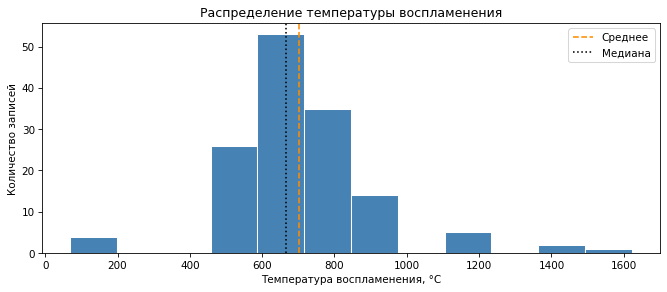

In [79]:
t = temperature["ignition_temperature_c"]

plt.figure(figsize=(9, 4))

plt.hist(t, bins=12, edgecolor="white", color="steelblue")
plt.axvline(t.mean(), color="darkorange", linestyle="--", label="Среднее")
plt.axvline(t.median(), color="black", linestyle=":", label="Медиана")

decorate(
    xlabel="Температура воспламенения, °C",
    ylabel="Количество записей",
    title="Распределение температуры воспламенения"
)

plt.legend()
plt.show()

На гистограмме основная масса температур сосредоточена примерно
между 450 и 970 °C. Наиболее высокий столбец соответствует
интервалу около 590–720 °C, в котором находятся и среднее,
и медиана.

Справа от основного скопления расположены немногочисленные высокие
значения, формирующие более протяжённый хвост. Это согласуется
с превышением среднего над медианой.

Общая гистограмма объединяет разные материалы и формы образцов.
Чтобы понять, как они представлены в распределении, далее
сравним температуры отдельно для bulk, chip и powders.



Дополнительно рассчитаем численность, среднее, медиану
и границы диапазона для каждой группы.

,n,mean,median,minimum,maximum
geometry,,,,,
bulk,98,749.45,695.00,510.00,1622.55
chip,30,614.35,656.80,69.00,930.00
powders,12,534.58,527.61,485.47,574.88


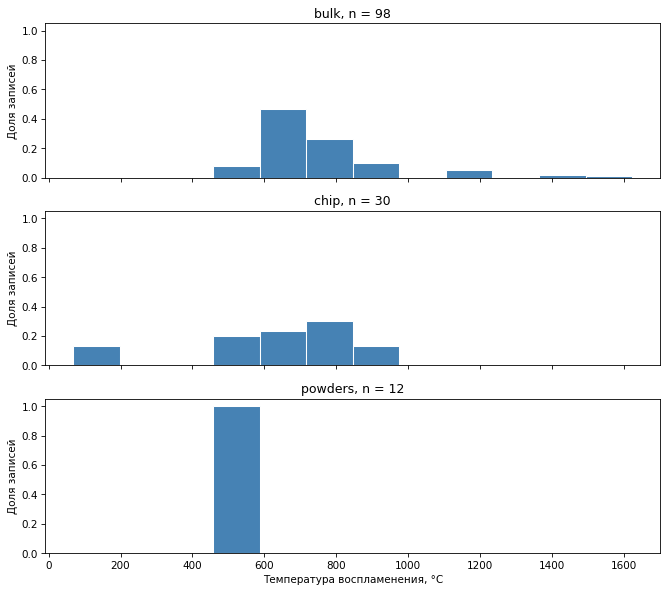

In [80]:
import numpy as np

geometry_order = ["bulk", "chip", "powders"]

geometry_summary = (
    temperature.groupby("geometry")["ignition_temperature_c"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        minimum="min",
        maximum="max"
    )
    .reindex(geometry_order)
)

display(geometry_summary.round(2))

bins = np.histogram_bin_edges(t, bins=12)

fig, axes = plt.subplots(
    3, 1, figsize=(9, 8), sharex=True, sharey=True
)

for ax, geometry in zip(axes, geometry_order):
    values = temperature.loc[
        temperature["geometry"].eq(geometry),
        "ignition_temperature_c"
    ]

    ax.hist(
        values,
        bins=bins,
        weights=np.ones(len(values)) / len(values),
        edgecolor="white",
        color="steelblue"
    )

    plt.sca(ax)
    decorate(
        title=f"{geometry}, n = {len(values)}",
        ylabel="Доля записей"
)

axes[-1].set_xlabel("Температура воспламенения, °C")

plt.tight_layout()
plt.show()

Разделение по форме образца показывает, как разные категории
участвуют в общем распределении. Высокотемпературный хвост относится
к bulk: в этой группе среднее 749,45 °C превышает медиану 695 °C.
Для chip наблюдается обратное соотношение: среднее 614,35 °C
ниже медианы 656,80 °C, что согласуется с наличием низких значений.

Для powders диапазон составляет 485,47–574,88 °C. При выбранном
разбиении все 12 записей попали в один интервал, поэтому этот
график не показывает различий внутри группы.

Диапазоны трёх категорий перекрываются. Наблюдаемые различия
нельзя приписать только форме образца: группы различаются также
материалами и условиями экспериментов. Для дальнейшего анализа
потребуется учитывать химический состав.

Одинаковая форма образца ещё не делает материалы сопоставимыми.
Посмотрим, какие материалы представлены в категории bulk
и для скольких записей содержание Mg превышает 50 мас. %.
Такое условие выделяет материалы с преобладанием магния
и не использует температуру при отборе.

In [81]:
bulk = temperature.loc[temperature["geometry"].eq("bulk")].copy()

display(
    bulk["material"]
    .value_counts()
    .rename_axis("Материал")
    .to_frame("Количество записей")
)

print("Всего записей bulk:", len(bulk))
print("С содержанием Mg > 50 мас. %:", bulk["Mg"].gt(50).sum())

display(
    bulk.loc[
        ~bulk["Mg"].gt(50),
        ["excel_row", "material", "Mg", "ignition_temperature_c"]
    ]
)

,Количество записей
Материал,
Mg alloys,13
Mg-nY,8
AZ91D+nCe,6
Mg-3Y-xCe,5
Mg-Ca HHR,3
...,...
AZX801,1
AZX802,1
Fe,1


Всего записей bulk: 98
С содержанием Mg > 50 мас. %: 95


,excel_row,material,Mg,ignition_temperature_c
137,140,Fe,0.0,1426.85
138,141,S355J2 carbon steel,0.0,1426.85
139,142,316 stainless steel,0.0,1622.55


Из 98 записей bulk в 95 содержание магния превышает 50 мас. %.
Оставшиеся три относятся к железу и двум сталям. Их температуры
воспламенения составляют 1426,85–1622,55 °C и образуют крайний
правый участок общей гистограммы.

Дальше сосредоточимся на bulk с содержанием Mg > 50 мас. %.
Так мы сможем подробнее изучить температуры материалов на
магниевой основе. При этом составы сплавов и условия испытаний
внутри выбранной группы различаются. Эти различия потребуется
учесть при объяснении разброса температур.

In [82]:
magnesium_bulk = bulk.loc[bulk["Mg"].gt(50)].copy()
t_mg = magnesium_bulk["ignition_temperature_c"]

display(t_mg.describe().to_frame("Температура, °C"))

print(
    "Исходных публикаций:",
    magnesium_bulk["source_reference"].nunique()
)

print(
    "Записей с ограничениями состава:",
    magnesium_bulk["has_composition_limit"].sum()
)

,"Температура, °C"
count,95.000000
mean,726.002942
std,145.990814
min,510.000000
25%,640.088397
50%,680.000000
75%,774.695037
max,1219.000000


Исходных публикаций: 20
Записей с ограничениями состава: 13


В выбранной группе осталось 95 записей из 20 публикаций.
Температуры лежат в диапазоне от 510 до 1219 °C. По сравнению
со всей базой диапазон сузился, стандартное отклонение уменьшилось
с 207,62 до 145,99 °C.

Среднее выросло с 702,09 до 726,00 °C, медиана — с 665 до 680 °C.
При отборе исключились как три высокие температуры железа и сталей,
так и записи chip и powders, среди которых встречались низкие
значения. Поэтому сужение диапазона сопровождалось ростом среднего.

Центральная половина температур находится между 640,09 и 774,70 °C.
Среднее превышает медиану примерно на 46 °C. Посмотрим на гистограмму,
чтобы понять, как высокие значения расположены относительно
основной части группы.

В 13 записях некоторые доли элементов заданы верхними границами.
Все эти записи сохраним: значения температуры в них доступны.

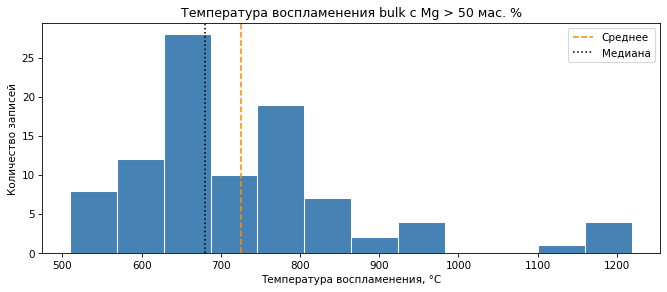

In [83]:
plt.figure(figsize=(9, 4))

plt.hist(t_mg, bins=12, edgecolor="white", color="steelblue")
plt.axvline(t_mg.mean(), color="darkorange", linestyle="--", label="Среднее")
plt.axvline(t_mg.median(), color="black", linestyle=":", label="Медиана")

decorate(
    xlabel="Температура воспламенения, °C",
    ylabel="Количество записей",
    title="Температура воспламенения bulk с Mg > 50 мас. %"
)

plt.legend()
plt.show()

После отбора магниевых bulk правый хвост сохранился.
Большинство температур сосредоточено примерно между 600 и 850 °C,
но несколько значений превышают 1100 °C. Среднее 726 °C находится
правее медианы 680 °C.

Такую форму распределения называют правосторонней асимметрией:
со стороны высоких значений хвост длиннее. На графике также видны
несколько локальных пиков. Проверим, сохраняются ли они при другом
числе интервалов.

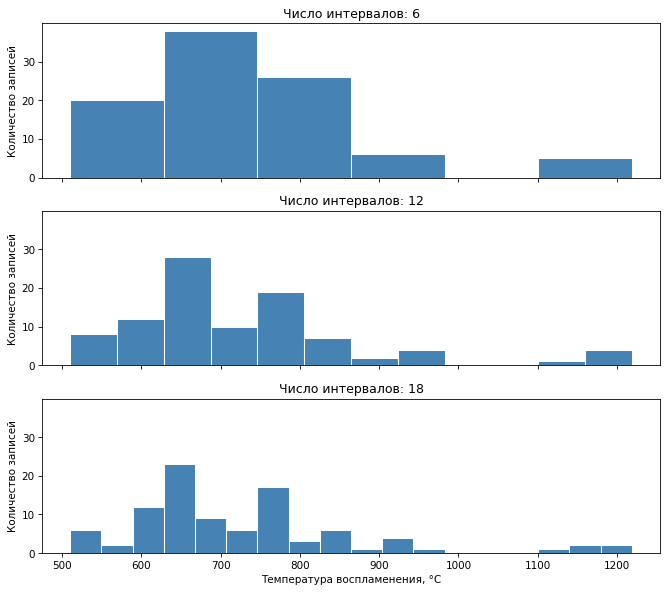

In [84]:
fig, axes = plt.subplots(
    3, 1, figsize=(9, 8), sharex=True, sharey=True
)

for ax, number_of_bins in zip(axes, [6, 12, 18]):
    ax.hist(
        t_mg,
        bins=number_of_bins,
        edgecolor="white",
        color="steelblue"
    )

    plt.sca(ax)
    decorate(
        title=f"Число интервалов: {number_of_bins}",
        ylabel="Количество записей"
    )

axes[-1].set_xlabel("Температура воспламенения, °C")

plt.tight_layout()
plt.show()

При всех трёх разбиениях основное скопление температур находится
примерно между 600 и 850 °C. Несколько высоких значений образуют
правый хвост, отделённый от остальных наблюдений пустым участком
около 1000–1100 °C.

При шести интервалах основная часть распределения выглядит
как одна широкая вершина. При 12 и 18 интервалах становятся
заметны пики около 650 и 780 °C. Их выраженность зависит
от разбиения, поэтому пока рано связывать каждый пик
с отдельной группой материалов.

Далее подробнее рассмотрим высокие температуры: какие образцы
и публикации им соответствуют.

Выделим значения за границами Q₁ − 1,5IQR и Q₃ + 1,5IQR.
Это распространённое правило поиска потенциальных выбросов.
Посмотрим, какие материалы и публикации соответствуют этим значениям.

In [85]:
q1, q3 = t_mg.quantile([0.25, 0.75])
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_mask = (t_mg < lower_bound) | (t_mg > upper_bound)

print(f"Нижняя граница: {lower_bound:.2f} °C")
print(f"Верхняя граница: {upper_bound:.2f} °C")

display(
    magnesium_bulk.loc[
        outlier_mask,
        [
            "excel_row",
            "material",
            "ignition_temperature_c",
            "sample_size",
            "source_reference"
        ]
    ].sort_values("ignition_temperature_c")
)

Нижняя граница: 438.18 °C
Верхняя граница: 976.60 °C


,excel_row,material,ignition_temperature_c,sample_size,source_reference
99,102,Mg-3Y-xCe,1123.280000,20×20×5,[24]
97,100,Mg-3Y-xCe,1164.570000,20×20×5,[24]
101,104,Mg-3Y-xCe,1166.630000,20×20×5,[24]
52,55,AZ91-2Ca,1209.125475,10×10×5,[16]
56,59,Mg-3Y-0.4Ca-0.2Ce,1219.000000,φ10×6,[19]


Границы составили 438,18 и 976,60 °C. Выше верхней границы
находятся пять значений от 1123,28 до 1219 °C — около 5,3%
выбранной группы.

Три записи относятся к серии Mg-3Y-xCe из публикации [24].
Ещё две — к AZ91-2Ca из [16] и Mg-3Y-0.4Ca-0.2Ce из [19].
Таким образом, высокотемпературный хвост представлен несколькими
составами и источниками.

Сохраним все 95 записей. Чтобы оценить влияние этих пяти значений
на сводные показатели, отдельно пересчитаем среднее, медиану
и стандартное отклонение без них.

In [86]:
t_without_outliers = t_mg.loc[~outlier_mask]

comparison = pd.DataFrame({
    "Все записи": [
        t_mg.size,
        t_mg.mean(),
        t_mg.median(),
        t_mg.std()
    ],
    "Без пяти высоких значений": [
        t_without_outliers.size,
        t_without_outliers.mean(),
        t_without_outliers.median(),
        t_without_outliers.std()
    ]
}, index=[
    "Количество записей",
    "Среднее, °C",
    "Медиана, °C",
    "Стандартное отклонение, °C"
])

display(comparison.round(2))

,Все записи,Без пяти высоких значений
Количество записей,95.00,90.00
"Среднее, °C",726.00,700.97
"Медиана, °C",680.00,677.43
"Стандартное отклонение, °C",145.99,102.02


Без пяти высоких значений среднее снизилось с 726,00 до 700,97 °C,
а медиана изменилась с 680,00 до 677,43 °C. В этом сравнении
медиана оказалась гораздо устойчивее к исключению крайних значений.

Стандартное отклонение уменьшилось со 145,99 до 102,02 °C.
Таким образом, пять записей заметно повышают среднее и общий
разброс температур. Дальнейший анализ продолжим по всем 95 записям.

Гистограмма объединяет температуры в интервалы. Таблица частот
позволит рассмотреть отдельные значения и узнать, сколько раз
каждое из них встречается.

Для её построения используем FreqTab из библиотеки empiricaldist.
Сохраним температуры с той точностью, с которой они записаны
в исходной таблице.

In [87]:
from empiricaldist import FreqTab

temperature_freq = FreqTab.from_seq(t_mg)

display(
    temperature_freq
    .sort_values(ascending=False)
    .head(10)
    .rename_axis("Температура, °C")
    .to_frame("Частота")
)

print("Всего записей:", temperature_freq.sum())
print("Различных температур:", len(temperature_freq))
print("Максимальная частота:", temperature_freq.max())

,Частота
"Температура, °C",
630.0,2
647.0,2
527.0,1
525.0,1
510.0,1
549.0,1
556.0,1
557.0,1
591.0,1


Всего записей: 95
Различных температур: 93
Максимальная частота: 2


На 95 записей приходится 93 различных значения температуры.
Только 630 и 647 °C встречаются дважды. По частоте отдельных
значений здесь трудно выделить характерную температуру:
почти каждое число встречается один раз.

Теперь разделим частоты на число записей. Получим относительные
частоты - доли наблюдений с каждой температурой. В третьей главе
Дауни такое распределение представлено объектом Pmf.

In [88]:
from empiricaldist import Pmf

temperature_pmf = Pmf.from_seq(t_mg)

display(
    pd.DataFrame({
        "Частота": temperature_freq,
        "Относительная частота": temperature_pmf
    })
    .sort_values("Частота", ascending=False)
    .head(10)
    .rename_axis("Температура, °C")
)

print("Сумма относительных частот:", temperature_pmf.sum())

,Частота,Относительная частота
"Температура, °C",,
630.0,2,0.021053
647.0,2,0.021053
527.0,1,0.010526
525.0,1,0.010526
510.0,1,0.010526
549.0,1,0.010526
556.0,1,0.010526
557.0,1,0.010526
591.0,1,0.010526


Сумма относительных частот: 1.0000000000000004


Температурам 630 и 647 °C соответствует по 2/95 ≈ 0,0211,
то есть по 2,11% записей. Для остальных значений относительная
частота равна 1/95 ≈ 0,0105. Сумма вероятностей равна единице
с учётом вычислительной погрешности: PMF нормирована.

Эти вероятности описывают равновероятный выбор записи из нашей
группы. Например, вероятность выбрать запись с температурой
630 °C составляет около 2,11%.

Сложив относительные частоты всех температур до выбранного порога
включительно, получим долю записей, не превышающих этот порог.
Так устроена интегральная функция распределения (CDF).
Построим её для магниевой группы.

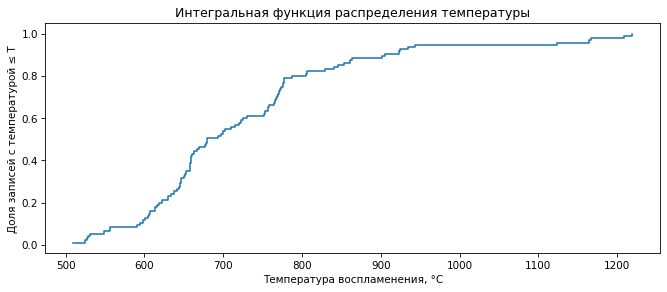

,"Порог, °C",Количество записей ≤ порога,Доля записей ≤ порога
0,650,31,0.3263157894736842
1,700,51,0.5368421052631579
2,800,76,0.8
3,1000,90,0.9473684210526315


In [89]:
from empiricaldist import Cdf

temperature_cdf = Cdf.from_seq(t_mg)

plt.figure(figsize=(9, 4))
temperature_cdf.step()

decorate(
    xlabel="Температура воспламенения, °C",
    ylabel="Доля записей с температурой ≤ T",
    title="Интегральная функция распределения температуры"
)

plt.show()

thresholds = [650, 700, 800, 1000]

display(pd.DataFrame({
    "Порог, °C": thresholds,
    "Количество записей ≤ порога": [
        t_mg.le(value).sum() for value in thresholds
    ],
    "Доля записей ≤ порога": [
        temperature_cdf(value) for value in thresholds
    ]
}))

Температура не превышает 700 °C в 51 из 95 записей — примерно
в 53,7% случаев. До 800 °C включительно находится 80% значений.
Выше 1000 °C остаются пять записей.

На участке примерно от 980 до 1120 °C график горизонтален:
температур в этом промежутке нет. Более крутые участки около
630–660 и 760–780 °C соответствуют скоплениям значений,
которые мы видели на гистограмме.

Попробуем описать температуры нормальным распределением.
У него два параметра: μ задаёт положение центра, σ — разброс.
Оценим их по нашим данным и наложим теоретическую ИФР
на эмпирическую. Посмотрим, на каких участках они расходятся.

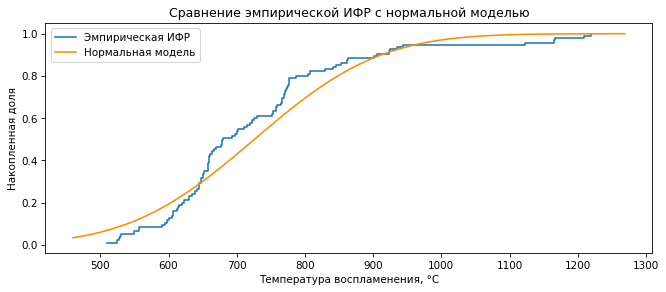

μ = 726.00 °C
σ = 145.22 °C


In [90]:
from scipy import stats

mu, sigma = stats.norm.fit(t_mg)
grid = np.linspace(t_mg.min() - 50, t_mg.max() + 50, 500)

plt.figure(figsize=(9, 4))

temperature_cdf.step(label="Эмпирическая ИФР")
plt.plot(
    grid,
    stats.norm.cdf(grid, loc=mu, scale=sigma),
    label="Нормальная модель",
    color="darkorange"
)

decorate(
    xlabel="Температура воспламенения, °C",
    ylabel="Накопленная доля",
    title="Сравнение эмпирической ИФР с нормальной моделью"
)

plt.legend()
plt.show()

print(f"μ = {mu:.2f} °C")
print(f"σ = {sigma:.2f} °C")

Для нормальной модели получили μ = 726,00 °C и σ = 145,22 °C.
Около 650–800 °C эмпирическая ИФР проходит преимущественно
выше теоретической: доля температур до соответствующих порогов
в данных больше, чем предсказывает модель.

После 950 °C нормальная ИФР быстро приближается к единице.
Эмпирическая кривая остаётся около 0,947 до следующих высоких
температур. Модель плохо передаёт расположение пяти значений
в правом хвосте.

Нормальная модель заметно расходится с данными в центральной части
и правом хвосте. Следом рассмотрим логнормальное распределение.
В нём логарифм исследуемой величины имеет нормальное распределение.

Для логнормальной модели переведём температуру в кельвины:
T_K = T_C + 273,15. Начало шкалы влияет на логарифмы,
поэтому выбор единиц здесь существенен.

Оценим параметры нормального распределения логарифмов температур,
а затем построим соответствующую логнормальную ИФР.
На графике температуры оставим в градусах Цельсия.

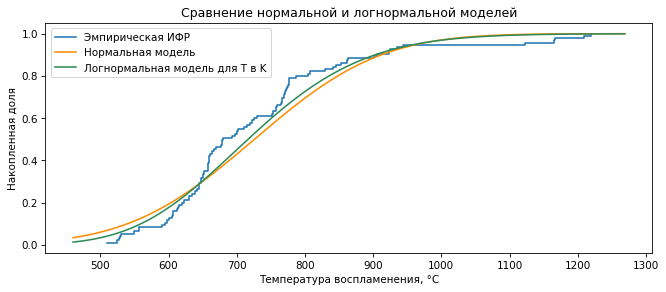

In [91]:
temperature_k = t_mg + 273.15
log_temperature = np.log(temperature_k)

mu_log, sigma_log = stats.norm.fit(log_temperature)

grid = np.linspace(t_mg.min() - 50, t_mg.max() + 50, 500)

plt.figure(figsize=(9, 4))

temperature_cdf.step(label="Эмпирическая ИФР")

plt.plot(
    grid,
    stats.norm.cdf(grid, loc=mu, scale=sigma),
    label="Нормальная модель",
    color="darkorange"
)

plt.plot(
    grid,
    stats.lognorm.cdf(
        grid + 273.15,
        s=sigma_log,
        loc=0,
        scale=np.exp(mu_log)
    ),
    label="Логнормальная модель для T в K",
    color="seagreen"
)

decorate(
    xlabel="Температура воспламенения, °C",
    ylabel="Накопленная доля",
    title="Сравнение нормальной и логнормальной моделей"
)

plt.legend()
plt.show()

Логнормальная модель немного приблизилась к эмпирической ИФР
на участке 650–800 °C. Однако обе модели сглаживают скопления
температур и продолжают расходиться с данными.

В правом хвосте обе кривые постепенно приближаются к единице,
тогда как эмпирическая ИФР образует длинный горизонтальный участок
перед пятью высокими значениями. Логнормальная модель также
не воспроизводит эту особенность.

Пока обе модели дают лишь приближённое описание распределения.

In [92]:
thresholds = np.array([650, 700, 800, 1000])

model_comparison = pd.DataFrame({
    "Порог, °C": thresholds,
    "Эмпирическая ИФР": [
        temperature_cdf(value) for value in thresholds
    ],
    "Нормальная модель": stats.norm.cdf(
        thresholds, loc=mu, scale=sigma
    ),
    "Логнормальная модель": stats.lognorm.cdf(
        thresholds + 273.15,
        s=sigma_log,
        loc=0,
        scale=np.exp(mu_log)
    )
})

display(model_comparison.round(4))

,"Порог, °C",Эмпирическая ИФР,Нормальная модель,Логнормальная модель
0,650,0.3263157894736842,0.3004,0.3026
1,700,0.5368421052631579,0.4289,0.4502
2,800,0.8,0.6948,0.7261
3,1000,0.9473684210526315,0.9704,0.9693


При пороге 700 °C эмпирическая доля составляет 53,7%.
Нормальная модель даёт 42,9%, логнормальная — 45,0%.
При 800 °C получаем соответственно 80,0%, 69,5% и 72,6%.
Обе модели недооценивают долю записей до этих температур.

При 1000 °C направление расхождения меняется: модели дают
около 97% при наблюдаемых 94,7%. Соответственно, долю температур
выше 1000 °C они недооценивают.

Во всех четырёх выбранных точках логнормальная модель оказалась
ближе к данным. По этому сравнению она выглядит предпочтительнее,
но заметные расхождения сохраняются.

До этого высота столбцов гистограммы показывала число записей.
Для сравнения с плотностями моделей изменим масштаб: суммарная
площадь столбцов будет равна единице.

При таком представлении площадь над интервалом температур
показывает долю наблюдений в нём. Для теоретической кривой
площадь под ней на том же интервале задаёт вероятность
попадания температуры в этот интервал.

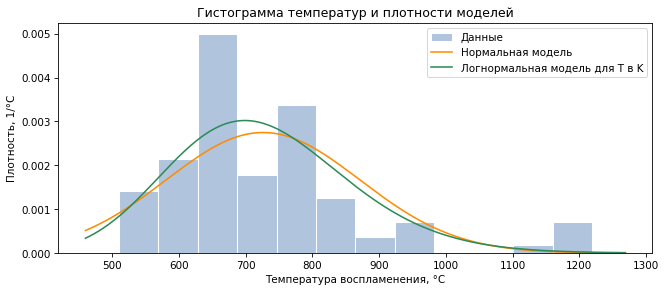

In [93]:
plt.figure(figsize=(9, 4))

plt.hist(
    t_mg,
    bins=12,
    density=True,
    edgecolor="white",
    color="lightsteelblue",
    label="Данные"
)

plt.plot(
    grid,
    stats.norm.pdf(grid, loc=mu, scale=sigma),
    color="darkorange",
    label="Нормальная модель"
)

plt.plot(
    grid,
    stats.lognorm.pdf(
        grid + 273.15,
        s=sigma_log,
        loc=0,
        scale=np.exp(mu_log)
    ),
    color="seagreen",
    label="Логнормальная модель для T в K"
)

decorate(
    xlabel="Температура воспламенения, °C",
    ylabel="Плотность, 1/°C",
    title="Гистограмма температур и плотности моделей"
)

plt.legend()
plt.show()

У логнормальной модели вершина немного выше и смещена в сторону
меньших температур по сравнению с нормальной. Обе кривые
сглаживают пики около 650 и 780 °C. Скопление высоких температур
около 1120–1220 °C также слабо отражено в моделях.

Попробуем оценить плотность непосредственно по данным с помощью
ядерной оценки плотности (ЯОП). Вокруг каждого наблюдения
размещается небольшая гладкая кривая; их усреднение даёт
общую оценку плотности. Ширина этих кривых определяет степень
сглаживания.

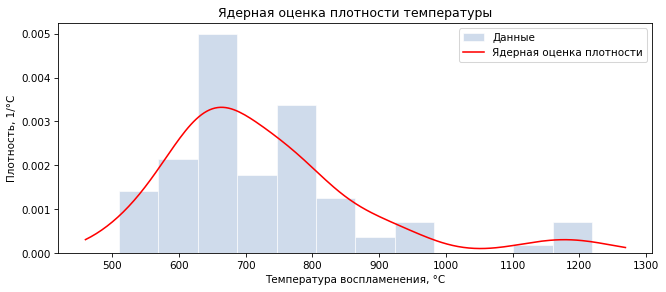

In [94]:
from scipy.stats import gaussian_kde
from thinkstats import Pdf

kde = gaussian_kde(t_mg)
domain = (grid.min(), grid.max())

temperature_pdf = Pdf(kde, domain, name="Ядерная оценка плотности")

plt.figure(figsize=(9, 4))

plt.hist(
    t_mg,
    bins=12,
    density=True,
    edgecolor="white",
    color="lightsteelblue",
    alpha=0.6,
    label="Данные"
)

temperature_pdf.plot(color="red")

decorate(
    xlabel="Температура воспламенения, °C",
    ylabel="Плотность, 1/°C",
    title="Ядерная оценка плотности температуры"
)

plt.legend()
plt.show()

Ядерная оценка плотности имеет основную вершину около 660 °C.
Скопление значений около 780 °C проявляется как более пологий
правый склон. Пять высоких температур образуют небольшой
отдельный подъём около 1180 °C.

Проверим, насколько этот вид кривой зависит от ширины сглаживания.
При меньшей ширине будут заметнее локальные скопления,
при большей кривая станет более плавной.

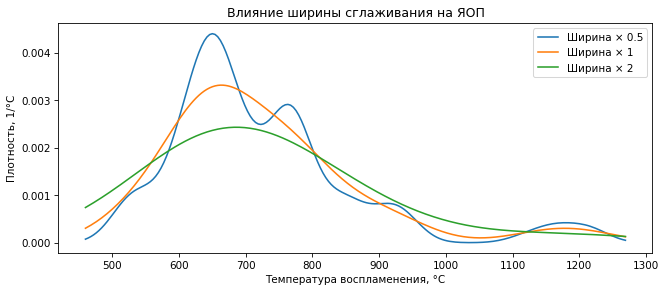

In [95]:
plt.figure(figsize=(9, 4))

for multiplier in [0.5, 1, 2]:
    kde_variant = gaussian_kde(
        t_mg,
        bw_method=lambda estimator: (
            estimator.scotts_factor() * multiplier
        )
    )

    pdf_variant = Pdf(
        kde_variant,
        domain,
        name=f"Ширина × {multiplier}"
    )

    pdf_variant.plot()

decorate(
    xlabel="Температура воспламенения, °C",
    ylabel="Плотность, 1/°C",
    title="Влияние ширины сглаживания на ЯОП"
)

plt.legend()
plt.show()

При ширине ×0,5 выделяются пики около 650 и 760 °C.
При стандартной ширине второй пик сглаживается, а при ×2
основная часть распределения превращается в одну широкую вершину.

Небольшой подъём около 1180 °C заметен при ширине ×0,5 и ×1.
При ×2 он почти исчезает. Число видимых вершин зависит
от настройки ЯОП, поэтому по ним трудно выделить устойчивые
группы материалов.

Теперь посмотрим, как температуры распределены по публикациям.
Возможно, отдельные скопления связаны с сериями из одних источников.

,n,minimum,median,maximum
source_reference,,,,
[13],1,525.00,525.00,525.00
[10],2,557.00,603.50,650.00
[23],14,510.00,609.50,651.00
[7],3,527.00,616.00,630.00
[11],2,600.76,622.38,644.00
[15],1,634.00,634.00,634.00
[14],1,652.47,652.47,652.47
[20],10,549.00,662.00,697.00
[28],3,556.00,667.00,769.00


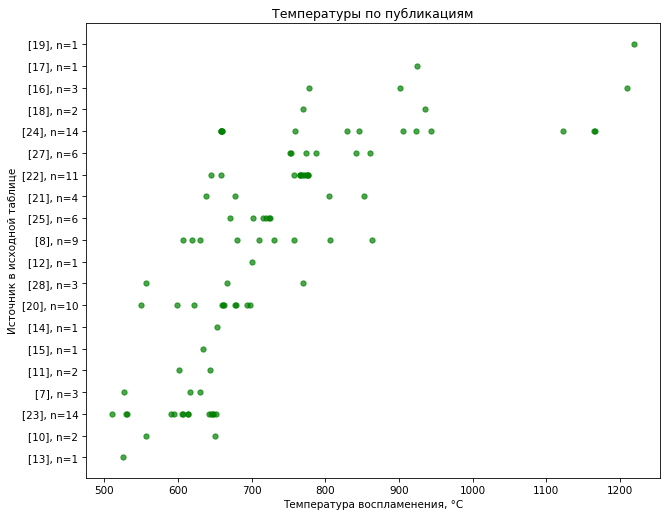

In [96]:
source_summary = (
    magnesium_bulk
    .groupby("source_reference")["ignition_temperature_c"]
    .agg(
        n="size",
        minimum="min",
        median="median",
        maximum="max"
    )
    .sort_values("median")
)

display(source_summary.round(2))

fig, ax = plt.subplots(figsize=(9, 7))

for position, source in enumerate(source_summary.index):
    values = magnesium_bulk.loc[
        magnesium_bulk["source_reference"].eq(source),
        "ignition_temperature_c"
    ]

    ax.scatter(
        values,
        np.full(len(values), position),
        color="green",
        alpha=0.7,
        s=25
    )

ax.set_yticks(
    range(len(source_summary)),
    [
        f"{source}, n={int(row['n'])}"
        for source, row in source_summary.iterrows()
    ]
)

plt.sca(ax)
decorate(
    xlabel="Температура воспламенения, °C",
    ylabel="Источник в исходной таблице",
    title="Температуры по публикациям"
)

plt.tight_layout()
plt.show()

Распределение записей по публикациям неравномерно. Источники [23]
и [24] содержат по 14 наблюдений, а несколько публикаций представлены
одной записью. Поэтому вклад источников в общее распределение
температуры различается.

Внутри [23] значения лежат примерно между 510 и 650 °C.
Источник [24] охватывает гораздо более широкий диапазон:
от температур около 660 °C до значений выше 1100 °C.
Высокие температуры также встречаются в [16] и [19].

Общий разброс складывается из различий между публикациями
и внутри отдельных источников. Объединение данных в магниевую
группу сохранило эту неоднородность.

Далее исследуем связи температуры с составом материалов
и поведение выборочных оценок.

### Independence & Estimations

В магниевой группе различаются доли легирующих элементов.
Рассмотрим алюминий: построим диаграмму рассеяния его содержания
и температуры воспламенения.

По горизонтали отложим содержание Al в мас. %, по вертикали -
температуру. Посмотрим, прослеживается ли общее направление
изменения температуры при увеличении доли алюминия.

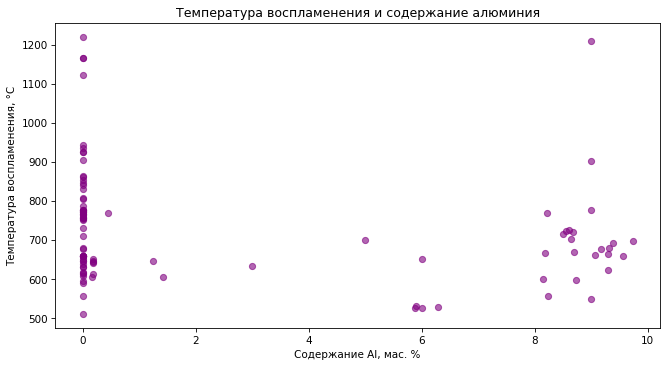

Количество пар наблюдений: 95


In [97]:
al_temperature = magnesium_bulk[
    ["Al", "ignition_temperature_c"]
].dropna()

plt.figure(figsize=(9, 5))

plt.scatter(
    al_temperature["Al"],
    al_temperature["ignition_temperature_c"],
    alpha=0.6,
    s=35,
    color="purple"
)

decorate(
    xlabel="Содержание Al, мас. %",
    ylabel="Температура воспламенения, °C",
    title="Температура воспламенения и содержание алюминия"
)

plt.show()

print("Количество пар наблюдений:", len(al_temperature))

Записи распределены по содержанию Al неравномерно: много значений
сосредоточено около нуля и в диапазоне 8–10 мас. %.
При близком содержании алюминия температуры заметно различаются.
Особенно широкий разброс наблюдается при Al = 0.

Рассчитаем два коэффициента корреляции. Коэффициент Пирсона
характеризует линейную связь. Коэффициент Спирмена рассчитывается
по рангам и показывает, насколько последовательно одна переменная
возрастает или убывает вместе с другой.

In [98]:
al = al_temperature["Al"]
temp = al_temperature["ignition_temperature_c"]

pearson_r = stats.pearsonr(al, temp).statistic
spearman_r = stats.spearmanr(al, temp).statistic

display(pd.Series({
    "Коэффициент Пирсона": pearson_r,
    "Коэффициент Спирмена": spearman_r
}).to_frame("Значение").round(3))

,Значение
Коэффициент Пирсона,-0.189
Коэффициент Спирмена,-0.339


Коэффициент Пирсона равен −0,189: линейная связь содержания Al
с температурой выражена слабо. Коэффициент Спирмена составляет
−0,339. В выбранной группе большему содержанию алюминия
в целом соответствуют более низкие позиции температур
в упорядоченном ряду, хотя разброс остаётся большим.

Эти коэффициенты описывают совместное изменение двух признаков
в собранных данных. Здесь также различаются остальные компоненты
сплавов и источники записей, поэтому выделить самостоятельное
влияние алюминия по этому сравнению нельзя.

Содержание Al и температура измеряются в разных единицах.
Переведём оба признака в стандартные оценки: из каждого значения
вычтем среднее и разделим результат на стандартное отклонение.

После преобразования значение будет показывать, на сколько
стандартных отклонений наблюдение удалено от среднего.
Проверим, изменится ли коэффициент Пирсона.

In [99]:
standardized = (
    al_temperature - al_temperature.mean()
) / al_temperature.std(ddof=0)

display(pd.DataFrame({
    "Среднее": standardized.mean(),
    "Стандартное отклонение": standardized.std(ddof=0)
}).round(6))

print(
    "Пирсон после стандартизации:",
    round(
        stats.pearsonr(
            standardized["Al"],
            standardized["ignition_temperature_c"]
        ).statistic,
        3
    )
)

,Среднее,Стандартное отклонение
Al,0.0,1.0
ignition_temperature_c,-0.0,1.0


Пирсон после стандартизации: -0.189


После стандартизации средние обоих признаков равны нулю,
стандартные отклонения - единице. Значение −0,0 в выводе
возникло из-за округления.

Коэффициент Пирсона сохранился: −0,189. Вычитание среднего
и деление на положительное стандартное отклонение изменили
масштаб признаков, сохранив их линейную корреляцию.

Для вычислительного эксперимента примем наши 95 температур
за конечную совокупность. Её среднее известно и равно примерно
726 °C. Будем случайно выбирать из неё записи и смотреть,
насколько выборочное среднее отличается от этого значения.

Начнём с выборки объёмом 10 с возвращением. После каждого выбора
запись остаётся доступной, поэтому одна запись может попасть
в выборку несколько раз.

In [100]:
rng = np.random.default_rng(42)

population = t_mg.to_numpy()
population_mean = population.mean()

sample = rng.choice(population, size=10, replace=True)
sample_mean = sample.mean()

display(pd.Series(sample, name="Температура, °C").to_frame())

print(f"Среднее совокупности: {population_mean:.2f} °C")
print(f"Выборочное среднее: {sample_mean:.2f} °C")
print(f"Ошибка оценки: {sample_mean - population_mean:.2f} °C")

,"Температура, °C"
0,806.850000
1,657.702122
2,595.000000
3,645.258621
4,645.258621
5,702.000000
6,806.850000
7,846.220000
8,634.000000
9,806.850000


Среднее совокупности: 726.00 °C
Выборочное среднее: 714.60 °C
Ошибка оценки: -11.40 °C


В выборке из 10 записей средняя температура составила 714,60 °C.
Ошибка оценки равна −11,40 °C: в этом отборе среднее оказалось
ниже значения для всех 95 записей.

Некоторые температуры повторяются, поскольку отбор проводился
с возвращением. При другом отборе состав выборки и её среднее
могут измениться. Повторим процедуру 1000 раз и посмотрим
на распределение полученных средних.

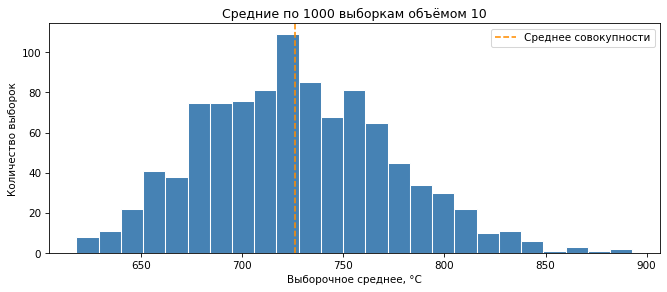

Среднее оценок: 726.60 °C
Средняя ошибка: 0.60 °C
Стандартное отклонение оценок: 46.99 °C


In [101]:
rng = np.random.default_rng(42)

samples = rng.choice(
    population,
    size=(1000, 10),
    replace=True
)

sample_means = samples.mean(axis=1)
errors = sample_means - population_mean

plt.figure(figsize=(9, 4))

plt.hist(
    sample_means,
    bins=25,
    edgecolor="white",
    color="steelblue"
)

plt.axvline(
    population_mean,
    color="darkorange",
    linestyle="--",
    label="Среднее совокупности"
)

decorate(
    xlabel="Выборочное среднее, °C",
    ylabel="Количество выборок",
    title="Средние по 1000 выборкам объёмом 10"
)

plt.legend()
plt.show()

print(f"Среднее оценок: {sample_means.mean():.2f} °C")
print(f"Средняя ошибка: {errors.mean():.2f} °C")
print(
    "Стандартное отклонение оценок:",
    f"{sample_means.std(ddof=1):.2f} °C"
)

Среднее по 1000 выборочным оценкам составило 726,60 °C.
Средняя ошибка равна 0,60 °C: завышения и занижения при повторных
отборах почти компенсировались.

При этом стандартное отклонение оценок составляет 46,99 °C.
Поэтому близость среднего результата к 726 °C ещё не означает,
что каждая выборка объёмом 10 даёт точную оценку.

Увеличим объём выборки и посмотрим, как изменится разброс средних.
Для каждого объёма повторим отбор с возвращением 1000 раз.

In [102]:
rng = np.random.default_rng(42)

sample_sizes = [5, 10, 20, 40, 60, 80, 95]
results = []

for n in sample_sizes:
    samples = rng.choice(
        population,
        size=(1000, n),
        replace=True
    )

    means = samples.mean(axis=1)
    estimation_errors = means - population_mean

    results.append({
        "Объём выборки": n,
        "Среднее оценок, °C": means.mean(),
        "Средняя ошибка, °C": estimation_errors.mean(),
        "Стандартное отклонение оценок, °C": means.std(ddof=1),
        "Теоретическая стандартная ошибка, °C":
            population.std(ddof=0) / np.sqrt(n)
    })

mean_estimation = pd.DataFrame(results)

display(mean_estimation.round(2))

,Объём выборки,"Среднее оценок, °C","Средняя ошибка, °C","Стандартное отклонение оценок, °C","Теоретическая стандартная ошибка, °C"
0,5,726.33,0.33,63.28,64.94
1,10,726.52,0.52,47.99,45.92
2,20,725.27,-0.73,32.49,32.47
3,40,727.41,1.41,22.79,22.96
4,60,725.60,-0.41,18.46,18.75
5,80,725.71,-0.29,15.61,16.24
6,95,725.88,-0.12,15.34,14.90


Средние оценок при всех объёмах остаются близкими к 726 °C.
При этом стандартное отклонение оценок уменьшается с 63,28 °C
для пяти записей до 15,34 °C для 95 записей. Значения близки
к рассчитанным по формуле σ/√n. Небольшие расхождения связаны
с конечным числом повторений.

Даже при n = 95 разброс сохраняется: отбор проводится
с возвращением, поэтому некоторые записи повторяются,
а другие могут отсутствовать.

Сравним этот результат с отбором без возвращения.
В каждой такой выборке одна запись может встретиться только один раз.
При n = 95 выборка будет содержать всю совокупность,
поэтому её среднее совпадёт со средним совокупности.

In [103]:
rng = np.random.default_rng(43)

results_without_replacement = []
population_size = len(population)
population_std = population.std(ddof=0)

for n in sample_sizes:
    means = np.array([
        rng.choice(population, size=n, replace=False).mean()
        for _ in range(1000)
    ])

    theoretical_se = (
        population_std / np.sqrt(n)
        * np.sqrt((population_size - n) / (population_size - 1))
    )

    results_without_replacement.append({
        "Объём выборки": n,
        "Среднее оценок, °C": means.mean(),
        "Стандартное отклонение оценок, °C": means.std(ddof=1),
        "Теоретическая стандартная ошибка, °C": theoretical_se
    })

mean_estimation_without_replacement = pd.DataFrame(
    results_without_replacement
)

display(mean_estimation_without_replacement.round(2))

,Объём выборки,"Среднее оценок, °C","Стандартное отклонение оценок, °C","Теоретическая стандартная ошибка, °C"
0,5,726.87,63.41,63.55
1,10,725.23,42.89,43.67
2,20,723.38,28.95,29.01
3,40,725.39,17.29,17.56
4,60,726.56,11.29,11.44
5,80,725.99,6.55,6.49
6,95,726.00,0.00,0.00


При отборе без возвращения разброс средних уменьшается быстрее.
Для выборок объёмом 80 стандартное отклонение оценок составляет
6,55 °C, тогда как при отборе с возвращением оно составляло
15,61 °C.

При объёме 95 каждая выборка содержит всю совокупность.
Среднее во всех повторениях равно 726 °C, стандартное отклонение
оценок равно нулю. Результаты моделирования близки к формуле
с поправкой на конечную совокупность.

Покажем оба способа отбора на одном графике.

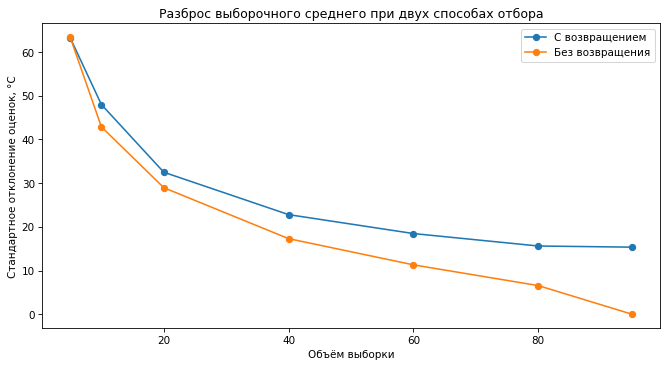

In [104]:
plt.figure(figsize=(9, 5))

plt.plot(
    mean_estimation["Объём выборки"],
    mean_estimation["Стандартное отклонение оценок, °C"],
    "o-",
    label="С возвращением"
)

plt.plot(
    mean_estimation_without_replacement["Объём выборки"],
    mean_estimation_without_replacement[
        "Стандартное отклонение оценок, °C"
    ],
    "o-",
    label="Без возвращения"
)

decorate(
    xlabel="Объём выборки",
    ylabel="Стандартное отклонение оценок, °C",
    title="Разброс выборочного среднего при двух способах отбора"
)

plt.legend()
plt.show()

При малых объёмах разброс оценок для двух способов отбора близок.
По мере увеличения выборки различие растёт. Без возвращения
выборка охватывает всё большую долю из 95 записей, и неопределённость
среднего постепенно исчезает. При отборе с возвращением повторы
сохраняют случайность состава даже при n = 95.

Перейдём от среднего к дисперсии. Она показывает разброс значений
вокруг среднего и измеряется в °C².

Сравним два способа расчёта: с делителем n и с делителем n − 1.

$$
v_n = \frac{1}{n}\sum_{i=1}^{n}(T_i-\overline T)^2,
\qquad
s^2 = \frac{1}{n-1}\sum_{i=1}^{n}(T_i-\overline T)^2.
$$

В Python этим вариантам соответствуют ddof=0 и ddof=1.
Для каждого объёма возьмём 1000 выборок с возвращением
и усредним полученные оценки дисперсии.

In [105]:
rng = np.random.default_rng(44)

population_variance = population.var(ddof=0)
variance_results = []

for n in sample_sizes:
    samples = rng.choice(
        population,
        size=(1000, n),
        replace=True
    )

    variance_n = samples.var(axis=1, ddof=0)
    variance_corrected = samples.var(axis=1, ddof=1)

    variance_results.append({
        "Объём выборки": n,
        "Средняя оценка с делителем n, °C²": variance_n.mean(),
        "Средняя оценка с делителем n−1, °C²":
            variance_corrected.mean(),
        "Теоретическое среднее для делителя n, °C²":
            (n - 1) / n * population_variance,
        "Дисперсия совокупности, °C²": population_variance
    })

variance_estimation = pd.DataFrame(variance_results)

display(variance_estimation.round(2))

,Объём выборки,"Средняя оценка с делителем n, °C²","Средняя оценка с делителем n−1, °C²","Теоретическое среднее для делителя n, °C²","Дисперсия совокупности, °C²"
0,5,17282.71,21603.38,16871.17,21088.97
1,10,19198.15,21331.28,18980.07,21088.97
2,20,19817.90,20860.95,20034.52,21088.97
3,40,20480.67,21005.82,20561.74,21088.97
4,60,20572.54,20921.22,20737.48,21088.97
5,80,20831.88,21095.57,20825.35,21088.97
6,95,20935.40,21158.12,20866.98,21088.97


Дисперсия совокупности составляет 21088,97 °C². При n = 5
средняя оценка с делителем n равна 17282,71 °C²,
с делителем n − 1 - 21603,38 °C².

Для делителя n результаты близки к теоретическим значениям
(n − 1)σ²/n. С увеличением объёма выборки ожидаемое занижение
уменьшается. Оценки с делителем n − 1 колеблются около дисперсии
совокупности. Усреднение по 1000 повторениям оставляет небольшую
случайную ошибку, поэтому точного совпадения здесь нет.

Теперь проверим точность отдельных оценок исправленной дисперсии
при увеличении объёма выборки.

Средние оценки могут быть близки к нужному значению даже при большом
разбросе отдельных результатов. Рассчитаем среднеквадратическую
ошибку исправленной дисперсии. Для удобства выразим её
в процентах от дисперсии совокупности.

,Объём выборки,"RMSE, °C²","RMSE относительно дисперсии, %"
0,5,20663.81,97.98
1,10,14274.90,67.69
2,20,10186.38,48.30
3,40,7224.68,34.26
4,60,5841.73,27.70
5,80,5149.64,24.42
6,95,4702.02,22.30


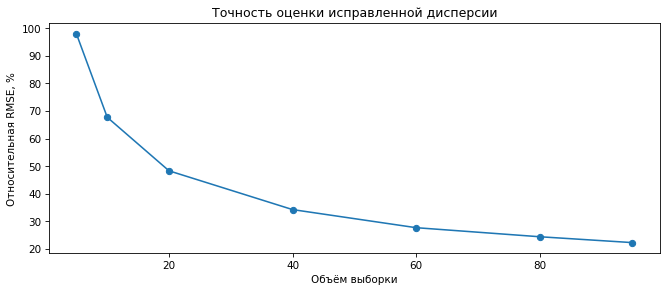

In [106]:
rng = np.random.default_rng(45)
variance_accuracy = []

for n in sample_sizes:
    samples = rng.choice(
        population,
        size=(1000, n),
        replace=True
    )

    estimates = samples.var(axis=1, ddof=1)
    rmse = np.sqrt(
        np.mean((estimates - population_variance) ** 2)
    )

    variance_accuracy.append({
        "Объём выборки": n,
        "RMSE, °C²": rmse,
        "RMSE относительно дисперсии, %":
            100 * rmse / population_variance
    })

variance_accuracy = pd.DataFrame(variance_accuracy)

display(variance_accuracy.round(2))

plt.figure(figsize=(9, 4))

plt.plot(
    variance_accuracy["Объём выборки"],
    variance_accuracy["RMSE относительно дисперсии, %"],
    "o-"
)

decorate(
    xlabel="Объём выборки",
    ylabel="Относительная RMSE, %",
    title="Точность оценки исправленной дисперсии"
)

plt.show()

При объёме 5 относительная RMSE составляет 97,98%:
отдельные оценки дисперсии сильно отклоняются от её значения
для совокупности. С увеличением выборки ошибка последовательно
уменьшается и при n = 95 составляет 22,30%.

Ранее средние исправленных оценок были близки к дисперсии
совокупности. Теперь видно, что точность отдельных оценок
существенно зависит от объёма выборки.

Полученный результат иллюстрирует состоятельность исправленной
дисперсии. Для независимых наблюдений из одного распределения
с конечной дисперсией эта оценка сходится по вероятности
к дисперсии при неограниченном увеличении объёма выборки.
В нашем моделировании независимость обеспечена отбором
с возвращением из фиксированных 95 записей.

Для независимых выборов с возвращением математическое ожидание
выборочного среднего равно среднему совокупности:

$$
\mathbb E[\overline T_n]=\mu.
$$

Следовательно, выборочное среднее является несмещённой оценкой.
Его дисперсия равна:

$$
\operatorname{Var}(\overline T_n)=\frac{\sigma^2}{n}.
$$

С ростом n дисперсия оценки стремится к нулю. По неравенству
Чебышёва для любого ε > 0:

$$
P\left(|\overline T_n-\mu|\geq\varepsilon\right)
\leq \frac{\sigma^2}{n\varepsilon^2}
\xrightarrow[n\to\infty]{}0.
$$

Это доказывает состоятельность выборочного среднего для нашей
схемы отбора. Уменьшение разброса средних в моделировании
согласуется с этим результатом.

При отборе с возвращением каждый раз случайно выбирается одна
из 95 записей. Предыдущие выборы не влияют на следующие,
поэтому выборы в моделировании независимы.

С исходными наблюдениями ситуация сложнее: несколько записей
взяты из одной публикации и могут относиться к общей серии опытов.
По имеющимся данным установить их независимость не удалось.
Корреляция Al и температуры также не отвечает на этот вопрос:
она характеризует связь состава с температурой.

**Проверка гипотезы о нормальном распределении**

Сравнение ИФР показало расхождения температур с нормальной моделью.
Проверим нормальность с помощью критерия Шапиро-Уилка.

H₀: наблюдения получены из нормального распределения.
H₁: распределение отличается от нормального.

Уровень значимости зададим заранее: α = 0,05.
Если p-value меньше α, отвергаем H₀. В противном случае
оснований отвергнуть её по этому критерию недостаточно.

Проверка предполагает независимые наблюдения из одного распределения.
Для нашей объединённой базы это допущение не установлено,
поэтому результат будем рассматривать вместе с графиками
и различиями между публикациями.

In [107]:
alpha = 0.05
normality_test = stats.shapiro(t_mg)

print(f"W = {normality_test.statistic:.4f}")
print(f"p-value = {normality_test.pvalue:.3e}")
print(f"Уровень значимости: {alpha}")

if normality_test.pvalue < alpha:
    print("Гипотеза H₀ отвергается.")
else:
    print("Оснований отвергнуть H₀ недостаточно.")

W = 0.8686
p-value = 1.115e-07
Уровень значимости: 0.05
Гипотеза H₀ отвергается.


Критерий Шапиро-Уилка дал W = 0,8686 и p ≈ 1,115 · 10⁻⁷.
Это меньше выбранного уровня значимости 0,05, поэтому
гипотезу нормального распределения отвергаем.

Результат согласуется с расхождениями на графиках ИФР и ФПВ.


Логнормальная модель была ближе к эмпирической ИФР в четырёх
выбранных точках. Проверим нормальность логарифмов температуры
в кельвинах - именно эту шкалу использовали при построении модели.

H₀: логарифм абсолютной температуры имеет нормальное распределение.
H₁: распределение логарифма отличается от нормального.

Сохраним уровень значимости α = 0,05. Условия применения критерия
и ограничения объединённой базы остаются прежними.

In [108]:
log_temperature = np.log(t_mg + 273.15)
lognormality_test = stats.shapiro(log_temperature)

print(f"W = {lognormality_test.statistic:.4f}")
print(f"p-value = {lognormality_test.pvalue:.3e}")
print(f"Уровень значимости: {alpha}")

if lognormality_test.pvalue < alpha:
    print("Гипотеза H₀ отвергается.")
else:
    print("Оснований отвергнуть H₀ недостаточно.")

W = 0.9239
p-value = 3.558e-05
Уровень значимости: 0.05
Гипотеза H₀ отвергается.


Для логарифма температуры в кельвинах критерий дал W = 0,9239
и p ≈ 3,558 · 10⁻⁵. При уровне значимости 0,05 гипотезу
нормальности логарифмов отвергаем.

Логнормальная модель оказалась ближе к данным в выбранных точках
ИФР, но проверка всё равно выявила расхождения. Обе рассмотренные
модели дают приближённое описание объединённой группы.
Выводы критерия сохраняют ограничения, связанные с независимостью
наблюдений и различиями между публикациями.

## Random Variable 02 (задержка воспламенения)

### Description

Второй величиной выбрали задержку воспламенения (ignition delay time) -
время от начала воздействия, вызывающего воспламенение, до момента
его регистрации.

Используем лист Ignition delay time из той же базы [3, 4].
Задержка записана в миллисекундах. Вместе с ней приведены состав,
форма и размер образца, давления компонентов газовой среды,
метод испытания и ссылка на публикацию.

Время до воспламенения зависит от материала и условий нагревания.
Сначала разберём устройство таблицы, затем выберем наблюдения
для подробного анализа.

### EDA & Distribution

In [109]:
delay_raw = pd.read_excel(
    url,
    sheet_name="Ignition delay time",
    header=None
)

display(delay_raw.head())
print("Размер таблицы:", delay_raw.shape)

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,NaN,Composition(wt.%),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,Sample geometry,Particle size(μm)/\nrod sample diameter(mm),Ignition delay time(ms),Xeff(%),Oxygen pressure(MPa),H2O pressure(MPa),N2 pressure(MPa),Ar pressure(MPa),Test method,Reference
1,Name,Al,Mg,Cu,Ti,W,B,Li,K,Cl,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,50,50,0,0,0,0,0,0,0,...,particle,52.844037,6.804124,22.8,0.00101,0,0,0,premixed flat flame buner,[29]
3,NaN,50,50,0,0,0,0,0,0,0,...,particle,74.93578,10.618557,22.8,0.00101,0,0,0,premixed flat flame buner,[29]
4,NaN,50,50,0,0,0,0,0,0,0,...,particle,90.862385,14.123711,22.8,0.00101,0,0,0,premixed flat flame buner,[29]


Размер таблицы: (278, 26)


На листе 276 строк данных. Помимо состава и задержки воспламенения,
здесь указаны размер образца, давления компонентов среды и метод
испытания. В первых трёх записях состав одинаковый, а размер частиц
и задержка различаются.

Названия материалов в этих строках отсутствуют, поэтому описывать
образцы будем также по столбцам состава. Создадим рабочую таблицу
и сохраним номера строк исходного Excel.

In [110]:
delay_elements = (
    delay_raw.iloc[1, 1:16].str.strip().tolist()
)

delay = delay_raw.iloc[2:].copy()

delay.columns = (
    ["material"]
    + delay_elements
    + [
        "geometry",
        "sample_size",
        "ignition_delay_ms",
        "xeff_percent",
        "oxygen_pressure_mpa",
        "water_pressure_mpa",
        "nitrogen_pressure_mpa",
        "argon_pressure_mpa",
        "test_method",
        "source_reference"
    ]
)

delay.insert(0, "excel_row", delay.index + 1)
delay = delay.reset_index(drop=True)

display(delay.head())

display(
    delay.isna().sum()
    .rename("Количество пропусков")
    .to_frame()
)

,excel_row,material,Al,Mg,Cu,Ti,W,B,Li,K,...,geometry,sample_size,ignition_delay_ms,xeff_percent,oxygen_pressure_mpa,water_pressure_mpa,nitrogen_pressure_mpa,argon_pressure_mpa,test_method,source_reference
0,3,NaN,50,50,0,0,0,0,0,0,...,particle,52.844037,6.804124,22.8,0.00101,0,0,0,premixed flat flame buner,[29]
1,4,NaN,50,50,0,0,0,0,0,0,...,particle,74.93578,10.618557,22.8,0.00101,0,0,0,premixed flat flame buner,[29]
2,5,NaN,50,50,0,0,0,0,0,0,...,particle,90.862385,14.123711,22.8,0.00101,0,0,0,premixed flat flame buner,[29]
3,6,NaN,50,50,0,0,0,0,0,0,...,particle,104.220183,17.42268,22.8,0.00101,0,0,0,premixed flat flame buner,[29]
4,7,NaN,50,50,0,0,0,0,0,0,...,particle,113.46789,19.896907,22.8,0.00101,0,0,0,premixed flat flame buner,[29]


,Количество пропусков
excel_row,0
material,179
Al,0
Mg,0
Cu,0
Ti,0
W,0
B,0
Li,0
K,0


Название материала отсутствует в 179 записях, значение GO -
в 167, метод испытания - в 17. Эти строки пока сохраняем.
Пропуски в GO оставим без изменений: из пустой ячейки нельзя
заключить, что содержание компонента равно нулю.

Задержка воспламенения, размер образца и давления заполнены
во всех строках. Проверим, встречаются ли в числовых столбцах
текстовые обозначения или ограничения.

In [111]:
delay_numeric_columns = delay_elements + [
    "sample_size",
    "ignition_delay_ms",
    "xeff_percent",
    "oxygen_pressure_mpa",
    "water_pressure_mpa",
    "nitrogen_pressure_mpa",
    "argon_pressure_mpa"
]

delay_numeric = delay[delay_numeric_columns].apply(
    pd.to_numeric, errors="coerce"
)

conversion_issues = []

for column in delay_numeric_columns:
    mask = delay[column].notna() & delay_numeric[column].isna()

    if mask.any():
        issues = delay.loc[mask, ["excel_row"]].copy()
        issues["column"] = column
        issues["original_value"] = delay.loc[mask, column]
        conversion_issues.append(issues)

if conversion_issues:
    display(pd.concat(conversion_issues, ignore_index=True))
else:
    print("Все непустые значения можно преобразовать в числа.")

,excel_row,column,original_value
0,170,sample_size,/
1,171,sample_size,/
2,172,sample_size,/
3,173,sample_size,/
4,174,sample_size,/
...,...,...,...
224,274,xeff_percent,/
225,275,xeff_percent,/
226,276,xeff_percent,/
227,277,xeff_percent,/


В числовых столбцах встречается символ /. Проверка через isna()
его не учитывала, поэтому первоначальная таблица пропусков
не отражала все отсутствующие числовые сведения.

Всего обнаружено 229 непреобразованных ячеек. Сгруппируем их
по столбцу и исходному обозначению, чтобы увидеть полный список.

In [112]:
delay_conversion_issues = pd.concat(
    conversion_issues,
    ignore_index=True
)

display(
    delay_conversion_issues
    .groupby(["column", "original_value"], dropna=False)
    .size()
    .rename("Количество")
    .to_frame()
)

,,Количество
column,original_value,
sample_size,/,109
xeff_percent,/,120


Символ / встречается в столбце размера образца 109 раз,
в Xeff - 120 раз. При подготовке числовой таблицы представим
эти обозначения как NaN. Исходные записи сохраняются в delay_raw.

В столбце задержки воспламенения доступны все 276 значений.
Теперь посмотрим, какие формы образцов представлены в базе
и как различаются их задержки.

In [113]:
delay[delay_numeric_columns] = delay_numeric

display(
    delay.groupby("geometry")["ignition_delay_ms"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        minimum="min",
        maximum="max"
    )
    .round(3)
)

print(
    "Лишних полных повторов:",
    delay_raw.iloc[2:].duplicated().sum()
)

,n,mean,median,minimum,maximum
geometry,,,,,
particle,156,23.271,21.395,4.026,63.368
particle blends,12,11.137,6.908,2.950,47.000
powder mixture,7,23.996,7.160,5.700,72.950
pressed powder pellet,80,49.841,10.431,3.748,627.300
rod,11,414.000,370.000,140.000,800.000
single droplet,10,1750.555,1630.862,1022.257,2765.256


Лишних полных повторов: 2


В базе представлены шесть категорий образцов. Самая многочисленная -
particle: 156 записей. Задержки rod и single droplet заметно выше,
чем у остальных категорий.

В pressed powder pellet среднее составляет 49,841 мс,
а медиана - 10,431 мс. Большое различие между ними указывает
на влияние высоких значений; максимум достигает 627,3 мс.

При проверке обнаружены два полных повтора строк.
Выведем совпадающие записи вместе с номерами строк Excel.

*Для нехимиков: [particle](https://en.wikipedia.org/wiki/Particle) - отдельная частица материала; [particle blends](https://en.wikipedia.org/wiki/Powder_mixture) - смесь частиц разных компонентов; [powder mixture](https://en.wikipedia.org/wiki/Powder_mixture) - смесь порошков; [pressed powder pellet](https://en.wikipedia.org/wiki/Powder_metallurgy#Powder_compaction) - таблетка из спрессованного порошка; [rod](https://en.wikipedia.org/wiki/Bar_stock) - образец в форме стержня или прутка; [single droplet](https://en.wikipedia.org/wiki/Drop_(liquid)) - отдельная капля.*

In [114]:
delay_duplicate_mask = (
    delay_raw.iloc[2:]
    .duplicated(keep=False)
    .to_numpy()
)

display(
    delay.loc[
        delay_duplicate_mask,
        [
            "excel_row",
            "material",
            "Al",
            "Mg",
            "geometry",
            "sample_size",
            "ignition_delay_ms",
            "test_method",
            "source_reference"
        ]
    ].sort_values(
        ["source_reference", "ignition_delay_ms", "excel_row"]
    )
)

,excel_row,material,Al,Mg,geometry,sample_size,ignition_delay_ms,test_method,source_reference
162,165,NaN,0.0,0,rod,3.2,140.0,promoted ignition-combustion test,[32]
166,169,NaN,0.0,0,rod,3.2,140.0,promoted ignition-combustion test,[32]
161,164,NaN,0.0,0,rod,3.2,370.0,promoted ignition-combustion test,[32]
165,168,NaN,0.0,0,rod,3.2,370.0,promoted ignition-combustion test,[32]


In [115]:
delay_keep_mask = (
    ~delay_raw.iloc[2:].duplicated(keep="first")
).to_numpy()

delay_clean = delay.loc[delay_keep_mask].copy()

print("До удаления повторов:", len(delay))
print("После удаления повторов:", len(delay_clean))

display(
    delay_clean.groupby("geometry")["ignition_delay_ms"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        minimum="min",
        maximum="max"
    )
    .round(3)
)

До удаления повторов: 276
После удаления повторов: 274


,n,mean,median,minimum,maximum
geometry,,,,,
particle,156,23.271,21.395,4.026,63.368
particle blends,12,11.137,6.908,2.950,47.000
powder mixture,7,23.996,7.160,5.700,72.950
pressed powder pellet,80,49.841,10.431,3.748,627.300
rod,9,449.333,446.000,140.000,800.000
single droplet,10,1750.555,1630.862,1022.257,2765.256


После удаления повторов осталось 274 записи. Сравним задержки
по форме образца. На обычной шкале значения в несколько миллисекунд
окажутся слишком близко друг к другу из-за задержек свыше 1000 мс.

Используем логарифмическую шкалу: одинаковые расстояния на оси
будут соответствовать одинаковому увеличению в разах.
Например, расстояния от 1 до 10 мс и от 10 до 100 мс будут равны.
Сами значения задержек остаются в миллисекундах.

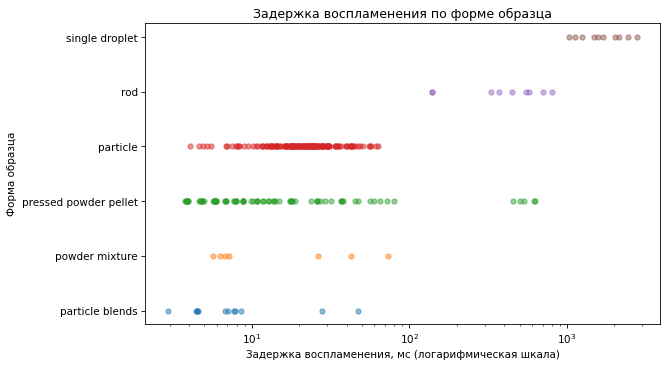

In [116]:
geometry_order = (
    delay_clean.groupby("geometry")["ignition_delay_ms"]
    .median()
    .sort_values()
    .index
)

fig, ax = plt.subplots(figsize=(9, 5))

for position, geometry in enumerate(geometry_order):
    values = delay_clean.loc[
        delay_clean["geometry"].eq(geometry),
        "ignition_delay_ms"
    ]

    ax.scatter(
        values,
        np.full(len(values), position),
        alpha=0.5,
        s=25,
        label=None
    )

ax.set_xscale("log")
ax.set_yticks(range(len(geometry_order)), geometry_order)

plt.sca(ax)
decorate(
    xlabel="Задержка воспламенения, мс (логарифмическая шкала)",
    ylabel="Форма образца",
    title="Задержка воспламенения по форме образца"
)

plt.tight_layout()
plt.show()

У particle задержки лежат примерно между 4 и 63 мс.
Диапазоны particle blends и powder mixture частично перекрываются
с ними. Для rod задержки составляют 140–800 мс,
для single droplet превышают 1000 мс.

Pressed powder pellet охватывает значения от нескольких
до нескольких сотен миллисекунд. Даже внутри одной категории
задержки могут существенно различаться.

Для подробного анализа рассмотрим particle - самую многочисленную
категорию. Посмотрим, какие составы и условия представлены
в её 156 записях.

In [117]:
delay_particles = delay_clean.loc[
    delay_clean["geometry"].eq("particle")
].copy()

display(
    delay_particles["source_reference"]
    .value_counts()
    .rename_axis("Источник")
    .to_frame("Количество записей")
)

display(
    delay_particles.groupby(["Al", "Mg"], dropna=False)
    .agg(
        n=("ignition_delay_ms", "size"),
        sources=("source_reference", "nunique"),
        minimum_ms=("ignition_delay_ms", "min"),
        maximum_ms=("ignition_delay_ms", "max")
    )
    .round(3)
)

display(
    delay_particles["test_method"]
    .value_counts(dropna=False)
    .rename_axis("Метод испытания")
    .to_frame("Количество записей")
)

,Количество записей
Источник,
[29],101
[30],55


,,n,sources,minimum_ms,maximum_ms
Al,Mg,,,,
50.0,50,101,1,4.026,63.368
100.0,0,55,1,8.082,42.000


,Количество записей
Метод испытания,
premixed flat flame buner,156


Категория particle объединяет две группы. В источнике [29]
представлена 101 запись с составом 50 мас. % Al и 50 мас. % Mg.
В источнике [30] находятся 55 записей с содержанием Al 100 мас. %.
Для всех указан метод premixed flat flame buner.

Дальше рассмотрим частицы Al из [30]. Задержки в этой группе
лежат между 8,082 и 42 мс. Проверим, как внутри неё меняются
размер частиц и условия газовой среды.

In [118]:
delay_al = delay_particles.loc[
    delay_particles["Al"].eq(100)
    & delay_particles["Mg"].eq(0)
    & delay_particles["source_reference"].eq("[30]")
].copy()

t_delay = delay_al["ignition_delay_ms"]

display(t_delay.describe().to_frame("Задержка, мс"))

conditions = [
    "sample_size",
    "xeff_percent",
    "oxygen_pressure_mpa",
    "water_pressure_mpa",
    "nitrogen_pressure_mpa",
    "argon_pressure_mpa"
]

display(
    delay_al[conditions]
    .agg(["count", "nunique", "min", "max"])
    .T
    .rename(columns={
        "count": "Заполнено",
        "nunique": "Различных значений",
        "min": "Минимум",
        "max": "Максимум"
    })
)

,"Задержка, мс"
count,55.000000
mean,21.141609
std,6.073526
min,8.081558
25%,17.742703
50%,21.219512
75%,24.745379
max,42.000000


,Заполнено,Различных значений,Минимум,Максимум
sample_size,55.0,55.0,54.176373,153.898828
xeff_percent,55.0,6.0,22.800000,49.100000
oxygen_pressure_mpa,55.0,6.0,0.001010,0.039700
water_pressure_mpa,55.0,1.0,0.000000,0.000000
nitrogen_pressure_mpa,55.0,1.0,0.000000,0.000000
argon_pressure_mpa,55.0,1.0,0.000000,0.000000


Средняя задержка составляет 21,14 мс, медиана - 21,22 мс.
Центральная половина значений находится между 17,74 и 24,75 мс.
Полный диапазон шире: от 8,08 до 42 мс.

Размер частиц меняется от 54,18 до 153,90 мкм. Давление кислорода
и Xeff принимают по шесть различных значений. В столбцах давления
H₂O, N₂ и Ar во всех записях указаны нули.

Состав и метод испытания в выбранной группе одинаковы,
но размер частиц и условия среды различаются. Посмотрим,
как выглядит распределение задержек при объединении этих записей.

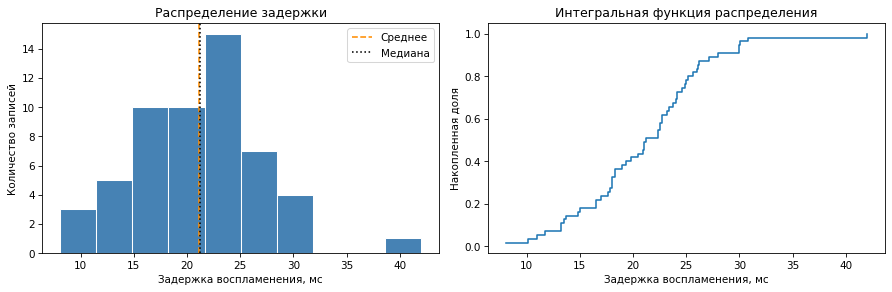

In [119]:
delay_cdf = Cdf.from_seq(t_delay)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    t_delay,
    bins=10,
    edgecolor="white",
    color="steelblue"
)

axes[0].axvline(
    t_delay.mean(),
    color="darkorange",
    linestyle="--",
    label="Среднее"
)

axes[0].axvline(
    t_delay.median(),
    color="black",
    linestyle=":",
    label="Медиана"
)

plt.sca(axes[0])
decorate(
    xlabel="Задержка воспламенения, мс",
    ylabel="Количество записей",
    title="Распределение задержки"
)
plt.legend()

plt.sca(axes[1])
delay_cdf.step()

decorate(
    xlabel="Задержка воспламенения, мс",
    ylabel="Накопленная доля",
    title="Интегральная функция распределения"
)

plt.tight_layout()
plt.show()

Основное скопление задержек находится примерно между 15 и 28 мс.
Среднее и медиана почти совпадают, однако справа выделяется
значение 42 мс. Между ним и остальными наблюдениями на ИФР
виден длинный горизонтальный участок.

Проверим крайние значения по правилу 1,5IQR и посмотрим,
каким размерам частиц и условиям среды они соответствуют.

In [120]:
delay_q1, delay_q3 = t_delay.quantile([0.25, 0.75])
delay_iqr = delay_q3 - delay_q1

delay_lower = delay_q1 - 1.5 * delay_iqr
delay_upper = delay_q3 + 1.5 * delay_iqr

delay_outlier_mask = (
    (t_delay < delay_lower)
    | (t_delay > delay_upper)
)

print(f"Нижняя граница: {delay_lower:.2f} мс")
print(f"Верхняя граница: {delay_upper:.2f} мс")

display(
    delay_al.loc[
        delay_outlier_mask,
        [
            "excel_row",
            "sample_size",
            "ignition_delay_ms",
            "xeff_percent",
            "oxygen_pressure_mpa",
            "source_reference"
        ]
    ].sort_values("ignition_delay_ms")
)

Нижняя граница: 7.24 мс
Верхняя граница: 35.25 мс


,excel_row,sample_size,ignition_delay_ms,xeff_percent,oxygen_pressure_mpa,source_reference
109,112,141.226994,42.0,22.8,0.00101,[30]


Границы по правилу 1,5IQR составили 7,24 и 35,25 мс.
За верхней границей находится одна запись с задержкой 42 мс:
размер частиц 141,23 мкм, давление кислорода 0,00101 МПа,
Xeff = 22,8%.

Запись соответствует выбранной группе частиц Al из [30].
Сохраним её и сравним показатели с результатами без этого значения.

In [121]:
delay_without_outlier = t_delay.loc[~delay_outlier_mask]

display(pd.DataFrame({
    "Все записи": [
        t_delay.size,
        t_delay.mean(),
        t_delay.median(),
        t_delay.std()
    ],
    "Без значения 42 мс": [
        delay_without_outlier.size,
        delay_without_outlier.mean(),
        delay_without_outlier.median(),
        delay_without_outlier.std()
    ]
}, index=[
    "Количество записей",
    "Среднее, мс",
    "Медиана, мс",
    "Стандартное отклонение, мс"
]).round(3))

,Все записи,Без значения 42 мс
Количество записей,55.000,54.000
"Среднее, мс",21.142,20.755
"Медиана, мс",21.220,21.110
"Стандартное отклонение, мс",6.074,5.406


Без задержки 42 мс среднее уменьшилось с 21,142 до 20,755 мс,
медиана - с 21,220 до 21,110 мс. Положение центра изменилось
незначительно. Сильнее изменился разброс: стандартное отклонение
снизилось с 6,074 до 5,406 мс.

Продолжим расчёты по всем 55 записям. Сравним эмпирическую ИФР
с нормальной и логнормальной моделями.

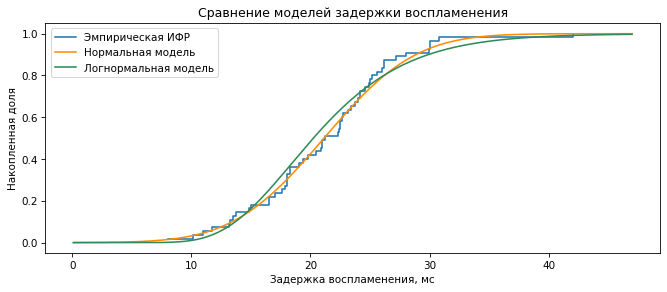

μ нормальной модели: 21.142 мс
σ нормальной модели: 6.018 мс


In [122]:
delay_mu, delay_sigma = stats.norm.fit(t_delay)

delay_log_mu, delay_log_sigma = stats.norm.fit(
    np.log(t_delay)
)

delay_grid = np.linspace(0.1, t_delay.max() + 5, 500)

plt.figure(figsize=(9, 4))

delay_cdf.step(label="Эмпирическая ИФР")

plt.plot(
    delay_grid,
    stats.norm.cdf(
        delay_grid,
        loc=delay_mu,
        scale=delay_sigma
    ),
    label="Нормальная модель",
    color="darkorange"
)

plt.plot(
    delay_grid,
    stats.lognorm.cdf(
        delay_grid,
        s=delay_log_sigma,
        loc=0,
        scale=np.exp(delay_log_mu)
    ),
    label="Логнормальная модель",
    color="seagreen"
)

decorate(
    xlabel="Задержка воспламенения, мс",
    ylabel="Накопленная доля",
    title="Сравнение моделей задержки воспламенения"
)

plt.legend()
plt.show()

print(f"μ нормальной модели: {delay_mu:.3f} мс")
print(f"σ нормальной модели: {delay_sigma:.3f} мс")

Нормальная и логнормальная модели близки к эмпирической ИФР
в основной части диапазона. Около 25–31 мс эмпирическая кривая
проходит выше обеих моделей: наблюдаемая доля задержек
до этих порогов больше предсказанной.

После 31 мс эмпирическая ИФР почти не меняется до значения 42 мс,
тогда как обе модели продолжают плавно возрастать.
По графику трудно уверенно выбрать одну из них.
Сравним доли при нескольких порогах.

In [123]:
delay_thresholds = np.array([15, 20, 25, 30])

display(pd.DataFrame({
    "Порог, мс": delay_thresholds,
    "Эмпирическая ИФР": [
        delay_cdf(value) for value in delay_thresholds
    ],
    "Нормальная модель": stats.norm.cdf(
        delay_thresholds,
        loc=delay_mu,
        scale=delay_sigma
    ),
    "Логнормальная модель": stats.lognorm.cdf(
        delay_thresholds,
        s=delay_log_sigma,
        loc=0,
        scale=np.exp(delay_log_mu)
    )
}).round(4))

,"Порог, мс",Эмпирическая ИФР,Нормальная модель,Логнормальная модель
0,15,0.18181818181818182,0.1537,0.1623
1,20,0.41818181818181815,0.4248,0.4842
2,25,0.7818181818181819,0.7393,0.7561
3,30,0.9454545454545454,0.9295,0.9020


При порогах 15 и 25 мс логнормальная модель ближе к эмпирической
ИФР. При 20 и 30 мс точнее нормальная модель. Наибольшее
расхождение среди выбранных точек возникает при 20 мс:
наблюдаемая доля составляет 41,8%, логнормальная модель даёт 48,4%.

По этим четырём порогам устойчивого преимущества одной модели
не видно. Сравним их ФПВ с гистограммой и ядерной оценкой плотности.

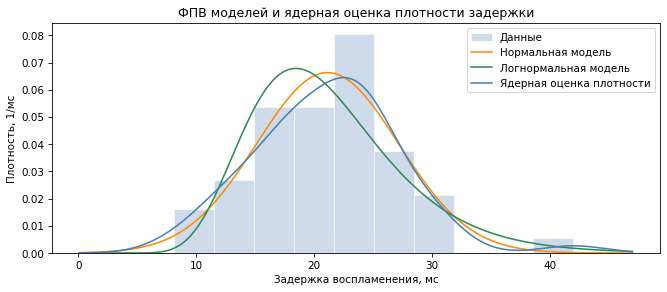

In [124]:
delay_kde = gaussian_kde(t_delay)
delay_pdf = Pdf(
    delay_kde,
    (delay_grid.min(), delay_grid.max()),
    name="Ядерная оценка плотности"
)

plt.figure(figsize=(9, 4))

plt.hist(
    t_delay,
    bins=10,
    density=True,
    edgecolor="white",
    color="lightsteelblue",
    alpha=0.6,
    label="Данные"
)

plt.plot(
    delay_grid,
    stats.norm.pdf(delay_grid, loc=delay_mu, scale=delay_sigma),
    color="darkorange",
    label="Нормальная модель"
)

plt.plot(
    delay_grid,
    stats.lognorm.pdf(
        delay_grid,
        s=delay_log_sigma,
        loc=0,
        scale=np.exp(delay_log_mu)
    ),
    color="seagreen",
    label="Логнормальная модель"
)

delay_pdf.plot(color="steelblue")

decorate(
    xlabel="Задержка воспламенения, мс",
    ylabel="Плотность, 1/мс",
    title="ФПВ моделей и ядерная оценка плотности задержки"
)

plt.legend()
plt.show()

Основная вершина ЯОП находится около 22 мс. Нормальная модель
проходит близко к ней, а логнормальная достигает максимума раньше -
около 18–19 мс. В центральной части нормальная модель выглядит
ближе к сглаженному распределению данных.

Значение 42 мс создаёт небольшой подъём ЯОП в правом хвосте.
Обе теоретические кривые на этом участке плавно убывают.

### Independence & Estimations

В выбранной группе размер частиц меняется от 54,18 до 153,90 мкм.
Посмотрим, как с ним связана задержка воспламенения.


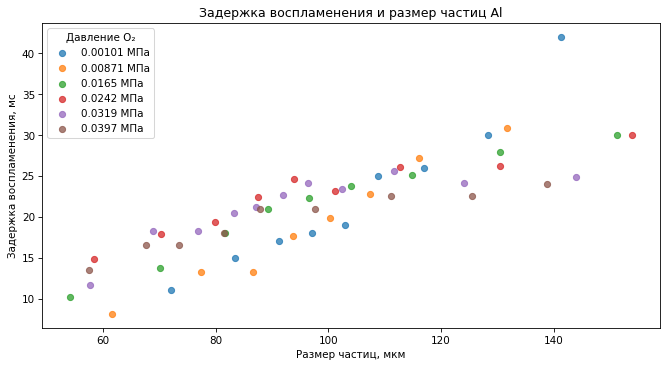

In [125]:
plt.figure(figsize=(9, 5))

for pressure, group in delay_al.groupby("oxygen_pressure_mpa"):
    plt.scatter(
        group["sample_size"],
        group["ignition_delay_ms"],
        s=35,
        alpha=0.75,
        label=f"{pressure:g} МПа"
    )

decorate(
    xlabel="Размер частиц, мкм",
    ylabel="Задержка воспламенения, мс",
    title="Задержка воспламенения и размер частиц Al"
)

plt.legend(title="Давление O₂")
plt.show()

С увеличением размера частиц задержка воспламенения в целом растёт.
У частиц размером около 60 мкм она составляет примерно 10–15 мс,
а около 150 мкм - 25–30 мс. Похожее направление видно
и внутри нескольких групп давления.

Задержка 42 мс при размере 141,23 мкм выделяется над остальными
точками. Рассчитаем корреляции для всей группы и отдельно
для каждого указанного давления кислорода.

In [126]:
delay_correlations = []

groups = [("Все записи", delay_al)] + [
    (f"{pressure:g} МПа", group)
    for pressure, group in delay_al.groupby("oxygen_pressure_mpa")
]

for name, group in groups:
    pairs = group[["sample_size", "ignition_delay_ms"]].dropna()

    delay_correlations.append({
        "Группа": name,
        "Количество записей": len(pairs),
        "Пирсон": stats.pearsonr(
            pairs["sample_size"],
            pairs["ignition_delay_ms"]
        ).statistic,
        "Спирмен": stats.spearmanr(
            pairs["sample_size"],
            pairs["ignition_delay_ms"]
        ).statistic
    })

display(
    pd.DataFrame(delay_correlations)
    .set_index("Группа")
    .round(3)
)

,Количество записей,Пирсон,Спирмен
Группа,,,
Все записи,55,0.856,0.894
0.00101 МПа,9,0.969,1.000
0.00871 МПа,8,0.988,0.976
0.0165 МПа,9,0.973,1.000
0.0242 МПа,9,0.951,0.983
0.0319 МПа,11,0.839,0.950
0.0397 МПа,9,0.941,0.987


Для всех 55 записей коэффициент Пирсона равен 0,856,
Спирмена - 0,894. Большему размеру частиц обычно соответствует
большая задержка воспламенения.

Внутри групп давления коэффициенты Пирсона лежат между 0,839
и 0,988. Связь сохраняется во всех шести группах, поэтому
общая положительная корреляция не объясняется только различиями
между указанными давлениями.

При давлениях 0,00101 и 0,0165 МПа коэффициент Спирмена равен 1:
порядок задержек полностью совпадает с порядком размеров частиц.
При этом точки могут отклоняться от прямой, что отражается
в коэффициентах Пирсона.

In [127]:
delay_pair = delay_al[["sample_size", "ignition_delay_ms"]]

delay_standardized = (
    delay_pair - delay_pair.mean()
) / delay_pair.std(ddof=0)

display(pd.DataFrame({
    "Среднее": delay_standardized.mean(),
    "Стандартное отклонение": delay_standardized.std(ddof=0)
}).round(6))

print(
    "Пирсон после стандартизации:",
    round(
        stats.pearsonr(
            delay_standardized["sample_size"],
            delay_standardized["ignition_delay_ms"]
        ).statistic,
        3
    )
)

,Среднее,Стандартное отклонение
sample_size,-0.0,1.0
ignition_delay_ms,-0.0,1.0


Пирсон после стандартизации: 0.856


После стандартизации средние равны нулю, стандартные отклонения -
единице. Коэффициент Пирсона остался равен 0,856.

Для вычислительного эксперимента используем 55 задержек
со средним 21,142 мс. Для каждого объёма выборки повторим
отбор 1000 раз и рассчитаем средние.

Сравним два способа отбора. При отборе с возвращением записи
могут повторяться. Без возвращения каждая запись попадает
в одну выборку не более одного раза.

In [128]:
delay_population = t_delay.to_numpy()
delay_population_mean = delay_population.mean()

delay_sample_sizes = [5, 10, 20, 30, 40, 50, 55]
delay_sampling_results = []

rng = np.random.default_rng(46)

for replace, method in [
    (True, "С возвращением"),
    (False, "Без возвращения")
]:
    for n in delay_sample_sizes:
        if replace:
            samples = rng.choice(
                delay_population,
                size=(1000, n),
                replace=True
            )
            means = samples.mean(axis=1)
        else:
            means = np.array([
                rng.choice(
                    delay_population,
                    size=n,
                    replace=False
                ).mean()
                for _ in range(1000)
            ])

        delay_sampling_results.append({
            "Способ отбора": method,
            "Объём выборки": n,
            "Среднее оценок, мс": means.mean(),
            "Средняя ошибка, мс":
                means.mean() - delay_population_mean,
            "Стандартное отклонение оценок, мс":
                means.std(ddof=1)
        })

delay_sampling = pd.DataFrame(delay_sampling_results)

display(delay_sampling.round(3))

,Способ отбора,Объём выборки,"Среднее оценок, мс","Средняя ошибка, мс","Стандартное отклонение оценок, мс"
0,С возвращением,5,20.974,-0.167,2.580
1,С возвращением,10,21.171,0.029,1.919
2,С возвращением,20,21.166,0.024,1.338
3,С возвращением,30,21.121,-0.020,1.126
4,С возвращением,40,21.120,-0.021,0.958
5,С возвращением,50,21.173,0.031,0.847
6,С возвращением,55,21.167,0.026,0.833
7,Без возвращения,5,21.191,0.049,2.600
8,Без возвращения,10,21.101,-0.041,1.766
9,Без возвращения,20,21.084,-0.057,1.091


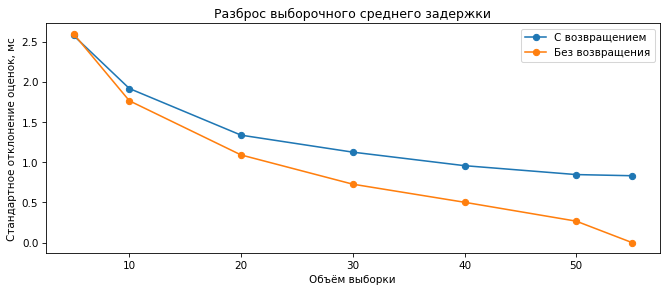

In [129]:
plt.figure(figsize=(9, 4))

for method, group in delay_sampling.groupby(
    "Способ отбора", sort=False
):
    plt.plot(
        group["Объём выборки"],
        group["Стандартное отклонение оценок, мс"],
        "o-",
        label=method
    )

decorate(
    xlabel="Объём выборки",
    ylabel="Стандартное отклонение оценок, мс",
    title="Разброс выборочного среднего задержки"
)

plt.legend()
plt.show()

С увеличением выборки стандартное отклонение средних уменьшается
при обоих способах отбора. При малых объёмах результаты близки,
затем отбор без возвращения даёт всё меньший разброс.

При n = 55 выборка без возвращения содержит все записи,
поэтому её среднее каждый раз равно 21,142 мс.
С возвращением состав выборки продолжает меняться,
и разброс сохраняется.

Сравним оценки дисперсии с делителями n и n − 1.
Для каждого объёма возьмём 1000 выборок с возвращением.
Рассчитаем средние оценки и RMSE исправленной дисперсии.

In [130]:
rng = np.random.default_rng(47)

delay_population_variance = delay_population.var(ddof=0)
delay_variance_results = []

for n in delay_sample_sizes:
    samples = rng.choice(
        delay_population,
        size=(1000, n),
        replace=True
    )

    variance_n = samples.var(axis=1, ddof=0)
    variance_corrected = samples.var(axis=1, ddof=1)

    rmse = np.sqrt(np.mean(
        (variance_corrected - delay_population_variance) ** 2
    ))

    delay_variance_results.append({
        "Объём выборки": n,
        "Средняя оценка с делителем n, мс²": variance_n.mean(),
        "Средняя оценка с делителем n−1, мс²":
            variance_corrected.mean(),
        "Дисперсия совокупности, мс²": delay_population_variance,
        "Относительная RMSE, %":
            100 * rmse / delay_population_variance
    })

delay_variance_estimation = pd.DataFrame(
    delay_variance_results
)

display(delay_variance_estimation.round(3))

,Объём выборки,"Средняя оценка с делителем n, мс²","Средняя оценка с делителем n−1, мс²","Дисперсия совокупности, мс²","Относительная RMSE, %"
0,5,28.397,35.496,36.217,86.194
1,10,31.966,35.518,36.217,58.204
2,20,34.226,36.027,36.217,41.744
3,30,34.999,36.205,36.217,32.016
4,40,35.201,36.104,36.217,28.789
5,50,35.115,35.832,36.217,25.500
6,55,35.358,36.013,36.217,24.204


При n = 5 средняя оценка с делителем n составляет 28,397 мс²
при дисперсии совокупности 36,217 мс². С делителем n − 1
получаем 35,496 мс². При увеличении объёма ожидаемое занижение
для делителя n уменьшается.

Средние исправленные оценки остаются близкими к 36,217 мс².
Их относительная RMSE снижается с 86,2% при n = 5
до 24,2% при n = 55. Таким образом, увеличение выборки
повышает точность оценки дисперсии.

На графиках обе модели были близки к основной части распределения.
Проверим нормальность задержек и их логарифмов критерием
Шапиро-Уилка при α = 0,05.

В первом случае H₀ задаёт нормальное распределение задержки,
во втором - нормальное распределение её логарифма.
Частицы различаются размерами и условиями среды, поэтому
результаты относятся к объединённой группе из 55 записей.
Обычная интерпретация p-значений предполагает независимые
наблюдения из одного распределения.

In [131]:
delay_alpha = 0.05
delay_normality_results = []

for name, values in [
    ("Задержка", t_delay),
    ("Логарифм задержки", np.log(t_delay))
]:
    result = stats.shapiro(values)

    delay_normality_results.append({
        "Проверяемая величина": name,
        "W": result.statistic,
        "p-значение": result.pvalue,
        "Решение при α = 0,05": (
            "H₀ отвергается"
            if result.pvalue < delay_alpha
            else "Оснований отвергнуть H₀ недостаточно"
        )
    })

display(
    pd.DataFrame(delay_normality_results)
    .set_index("Проверяемая величина")
)

,W,p-значение,"Решение при α = 0,05"
Проверяемая величина,,,
Задержка,0.971607,0.217168,Оснований отвергнуть H₀ недостаточно
Логарифм задержки,0.960904,0.071079,Оснований отвергнуть H₀ недостаточно


Для задержки критерий Шапиро-Уилка дал p = 0,217,
для логарифма задержки - p = 0,071. Оба значения превышают 0,05.
Оснований отвергнуть нормальную или логнормальную модель
по этой проверке недостаточно.

Такой результат не доказывает соответствие распределений моделям.
По большему p-значению также нельзя заключить, что нормальная
модель лучше логнормальной. На графике ФПВ нормальная модель
была ближе к основной вершине, а сравнение ИФР при выбранных
порогах не выявило устойчивого преимущества одной модели.

## Random Variable 03 (линейная скорость горения)

### Description

Третьей величиной выбрали линейную скорость горения -
расстояние, на которое фронт горения перемещается за единицу
времени.

Она зависит от состава материала, формы и размеров образца,
условий газовой среды. Используем данные из той же базы [3, 4].
Сначала посмотрим, какие характеристики и единицы измерения
указаны в таблице.

### EDA & Distribution

In [132]:
burning_raw = pd.read_excel(
    url,
    sheet_name="Combustion rate(volume)",
    header=None
)

display(burning_raw.head())
print("Размер таблицы:", burning_raw.shape)

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17
0,NaN,Composition(wt.%),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Oxygen pressure(MPa),Combustion Length(mm),Combustion rate(mm/s),Rod sample diameter(mm),Combustion rate(mm3/s),Reference
1,Name,Ti,Al,Cu,Si,V,Cr,Zr,Mg,Ni,Fe,C,NaN,NaN,NaN,NaN,NaN,NaN
2,Ti14,84.46,1.24,13.91,0.39,0,0,0,0,0,0,NaN,0.2,10,2.296875,3.2,18.4632,[38]
3,Ti14,84.46,1.24,13.91,0.39,0,0,0,0,0,0,NaN,0.2,20,3.765625,3.2,30.2696,[38]
4,Ti14,84.46,1.24,13.91,0.39,0,0,0,0,0,0,NaN,0.2,30,5,3.2,40.192,[38]


Размер таблицы: (170, 18)


Лист содержит состав материала, давление кислорода, длину и диаметр
стержня, линейную и объёмную скорости горения. Первые две строки
занимают заголовки. Для анализа выберем линейную скорость в мм/с.

In [133]:
burning = burning_raw.iloc[2:].copy()

burning.columns = [
    "material",
    "Ti", "Al", "Cu", "Si", "V", "Cr", "Zr", "Mg", "Ni", "Fe", "C",
    "oxygen_pressure_mpa",
    "combustion_length_mm",
    "burning_rate_mm_s",
    "rod_diameter_mm",
    "burning_rate_mm3_s",
    "source_reference"
]

burning.insert(0, "excel_row", burning.index + 1)
burning = burning.reset_index(drop=True)

display(burning.head())
print("Количество записей:", len(burning))
display(burning.isna().sum().to_frame("Количество пропусков"))

,excel_row,material,Ti,Al,Cu,Si,V,Cr,Zr,Mg,Ni,Fe,C,oxygen_pressure_mpa,combustion_length_mm,burning_rate_mm_s,rod_diameter_mm,burning_rate_mm3_s,source_reference
0,3,Ti14,84.46,1.24,13.91,0.39,0,0,0,0,0,0,NaN,0.2,10,2.296875,3.2,18.4632,[38]
1,4,Ti14,84.46,1.24,13.91,0.39,0,0,0,0,0,0,NaN,0.2,20,3.765625,3.2,30.2696,[38]
2,5,Ti14,84.46,1.24,13.91,0.39,0,0,0,0,0,0,NaN,0.2,30,5,3.2,40.192,[38]
3,6,Ti14,84.46,1.24,13.91,0.39,0,0,0,0,0,0,NaN,0.2,40,6.15625,3.2,49.4864,[38]
4,7,Ti14,84.46,1.24,13.91,0.39,0,0,0,0,0,0,NaN,0.3,10,2.921875,3.2,23.4872,[38]


Количество записей: 168


,Количество пропусков
excel_row,0
material,0
Ti,0
Al,0
Cu,0
Si,0
V,0
Cr,0
Zr,0
Mg,0


После удаления заголовков осталось 168 записей. В столбце содержания
углерода отсутствуют 48 значений. Пропуски сохраняем: отсутствие
значения не означает нулевое содержание компонента. Проверим,
содержат ли числовые столбцы текстовые обозначения.

In [134]:
burning_numeric_columns = [
    "Ti", "Al", "Cu", "Si", "V", "Cr", "Zr", "Mg", "Ni", "Fe", "C",
    "oxygen_pressure_mpa",
    "combustion_length_mm",
    "burning_rate_mm_s",
    "rod_diameter_mm",
    "burning_rate_mm3_s"
]

burning_conversion_issues = []

for column in burning_numeric_columns:
    original = burning[column].copy()
    converted = pd.to_numeric(original, errors="coerce")

    failed = original.notna() & converted.isna()

    if failed.any():
        issues = burning.loc[failed, ["excel_row"]].copy()
        issues["column"] = column
        issues["original_value"] = original.loc[failed]
        burning_conversion_issues.append(issues)

    burning[column] = converted

burning_conversion_issues = (
    pd.concat(burning_conversion_issues, ignore_index=True)
    if burning_conversion_issues
    else pd.DataFrame(columns=["excel_row", "column", "original_value"])
)

display(
    burning_conversion_issues
    .groupby(["column", "original_value"], dropna=False)
    .size()
    .rename("Количество")
    .to_frame()
)

Количество
column               original_value            
combustion_length_mm /                       45
                     25-30                    4

В столбце длины горения 45 значений обозначены символом `/`,
ещё четыре заданы интервалом 25–30 мм. При преобразовании они
стали пропусками; исходные обозначения сохранены отдельно.
Интервалы не заменяем их серединой. Эти строки сохраняем
для анализа скорости горения.

In [135]:
burning_data_columns = burning.columns.drop("excel_row")

print(
    "Лишних полных повторов:",
    burning.duplicated(subset=burning_data_columns).sum()
)

display(
    burning.groupby("material")
    .agg(
        n=("burning_rate_mm_s", "size"),
        mean=("burning_rate_mm_s", "mean"),
        median=("burning_rate_mm_s", "median"),
        minimum=("burning_rate_mm_s", "min"),
        maximum=("burning_rate_mm_s", "max"),
        n_sources=("source_reference", "nunique")
    )
    .round(3)
)

Лишних полных повторов: 0


,n,mean,median,minimum,maximum,n_sources
material,,,,,,
Al-Ni,4,128.571,115.584,64.935,218.182,1
BMG(Cu46Zr46Al8),7,8.971,8.348,7.071,11.092,1
Fe,27,8.655,8.988,4.018,12.808,1
Steel,18,12.306,11.392,3.953,29.968,1
Ti-12Cu,16,4.533,4.491,1.967,7.905,1
Ti-17Cu,16,4.031,4.155,1.848,6.472,1
Ti-22Cu,16,3.712,3.757,1.640,5.962,1
Ti-25V-10Cr,6,72.739,70.089,47.990,103.175,1
Ti-25V-15Cr,6,62.693,61.050,41.063,87.995,1


Полных повторов не обнаружено. Средние скорости существенно
различаются между материалами, поэтому общее распределение
будет объединять разные группы.

Для подробного анализа выберем сплавы Ti-2Cu, Ti-7Cu, Ti-12Cu,
Ti-17Cu и Ti-22Cu. Для каждого состава представлены 16 записей.
Проверим источники и условия испытаний выбранной серии.

In [136]:
ti_cu_materials = [
    "Ti-2Cu", "Ti-7Cu", "Ti-12Cu", "Ti-17Cu", "Ti-22Cu"
]

burning_ti_cu = burning.loc[
    burning["material"].isin(ti_cu_materials)
].copy()

print("Количество записей:", len(burning_ti_cu))

display(
    burning_ti_cu["source_reference"]
    .value_counts()
    .rename_axis("Источник")
    .to_frame("Количество записей")
)

display(
    burning_ti_cu.groupby("material")[
        ["oxygen_pressure_mpa", "combustion_length_mm", "rod_diameter_mm"]
    ]
    .agg(lambda values: sorted(values.dropna().unique()))
)

Количество записей: 80


,Количество записей
Источник,
[40],80


,oxygen_pressure_mpa,combustion_length_mm,rod_diameter_mm
material,,,
Ti-12Cu,"[0.1, 0.2, 0.3, 0.4]","[10.0, 20.0, 30.0, 40.0]",[3.2]
Ti-17Cu,"[0.1, 0.2, 0.3, 0.4]","[10.0, 20.0, 30.0, 40.0]",[3.2]
Ti-22Cu,"[0.1, 0.2, 0.3, 0.4]","[10.0, 20.0, 30.0, 40.0]",[3.2]
Ti-2Cu,"[0.1, 0.2, 0.3, 0.4]","[10.0, 20.0, 30.0, 40.0]",[3.2]
Ti-7Cu,"[0.1, 0.2, 0.3, 0.4]","[10.0, 20.0, 30.0, 40.0]",[3.2]


Выбранная серия содержит 80 записей из источника [40].
Для всех пяти сплавов диаметр стержня составляет 3,2 мм,
давление кислорода принимает значения от 0,1 до 0,4 МПа,
а длина горения — от 10 до 40 мм.

Распределение скорости в этой группе объединяет разные составы
и условия испытаний. Дальше учтём эти различия при анализе связей.

In [137]:
v_ti_cu = burning_ti_cu["burning_rate_mm_s"].dropna()

display(
    v_ti_cu.describe()
    .rename("Скорость горения, мм/с")
    .to_frame()
    .round(3)
)

print("Пропусков скорости:", burning_ti_cu["burning_rate_mm_s"].isna().sum())
print("Неположительных значений:", (v_ti_cu <= 0).sum())

,"Скорость горения, мм/с"
count,80.000
mean,4.325
std,1.576
min,1.640
25%,3.118
50%,4.247
75%,5.328
max,8.978


Пропусков скорости: 0
Неположительных значений: 0


Скорость горения изменяется от 1,640 до 8,978 мм/с.
Среднее составляет 4,325 мм/с, медиана - 4,247 мм/с,
стандартное отклонение - 1,576 мм/с. Центральные 50% значений
находятся между 3,118 и 5,328 мм/с.
Пропусков и неположительных значений скорости нет.

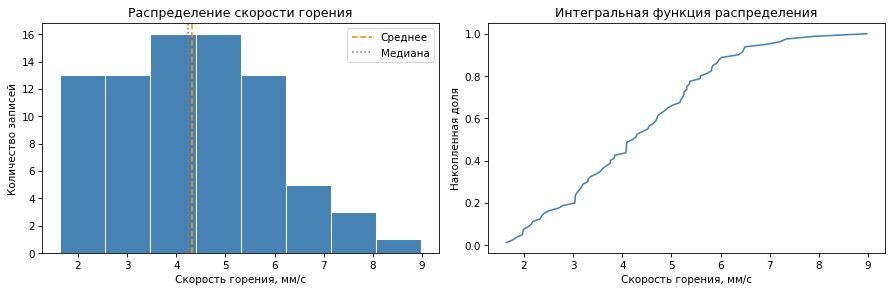

In [138]:
from empiricaldist import Cdf

v_cdf = Cdf.from_seq(v_ti_cu)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    v_ti_cu,
    bins="fd",
    color="steelblue",
    edgecolor="white"
)

axes[0].axvline(
    v_ti_cu.mean(),
    color="darkorange",
    linestyle="--",
    label="Среднее"
)

axes[0].axvline(
    v_ti_cu.median(),
    color="gray",
    linestyle=":",
    label="Медиана"
)

axes[0].set(
    title="Распределение скорости горения",
    xlabel="Скорость горения, мм/с",
    ylabel="Количество записей"
)
axes[0].legend()

v_cdf.plot(ax=axes[1], color="steelblue")

axes[1].set(
    title="Интегральная функция распределения",
    xlabel="Скорость горения, мм/с",
    ylabel="Накопленная доля"
)

plt.tight_layout()
plt.show()

Наибольшая частота наблюдается в интервалах около 4–5 мм/с.
Распределение имеет правый хвост: высокие скорости встречаются
реже, но достигают почти 9 мм/с. Среднее немного выше медианы.
Проверим крайние значения по правилу 1,5IQR.

In [139]:
v_q1 = v_ti_cu.quantile(0.25)
v_q3 = v_ti_cu.quantile(0.75)
v_iqr = v_q3 - v_q1

v_lower = v_q1 - 1.5 * v_iqr
v_upper = v_q3 + 1.5 * v_iqr

print(f"Нижняя граница: {v_lower:.3f} мм/с")
print(f"Верхняя граница: {v_upper:.3f} мм/с")

v_outliers = burning_ti_cu.loc[
    (burning_ti_cu["burning_rate_mm_s"] < v_lower)
    | (burning_ti_cu["burning_rate_mm_s"] > v_upper)
]

display(
    v_outliers[[
        "excel_row",
        "material",
        "oxygen_pressure_mpa",
        "combustion_length_mm",
        "rod_diameter_mm",
        "burning_rate_mm_s",
        "source_reference"
    ]]
)

Нижняя граница: -0.197 мм/с
Верхняя граница: 8.642 мм/с


,excel_row,material,oxygen_pressure_mpa,combustion_length_mm,rod_diameter_mm,burning_rate_mm_s,source_reference
63,66,Ti-7Cu,0.4,40.0,3.2,8.978261,[40]


Границы по правилу 1,5IQR составили -0,197 и 8,642 мм/с.
За верхней границей находится одна запись из источника [40]:
сплав Ti-7Cu, давление кислорода 0,4 МПа, длина горения 40 мм,
диаметр стержня 3,2 мм. Скорость горения - 8,978 мм/с.


In [140]:
v_without_outliers = v_ti_cu.loc[
    v_ti_cu.between(v_lower, v_upper)
]

v_sensitivity = pd.DataFrame({
    "Все записи": [
        v_ti_cu.size,
        v_ti_cu.mean(),
        v_ti_cu.median(),
        v_ti_cu.std(ddof=1)
    ],
    "Без крайнего значения": [
        v_without_outliers.size,
        v_without_outliers.mean(),
        v_without_outliers.median(),
        v_without_outliers.std(ddof=1)
    ]
}, index=[
    "Количество записей",
    "Среднее, мм/с",
    "Медиана, мм/с",
    "Стандартное отклонение, мм/с"
])

display(v_sensitivity.round(3))

,Все записи,Без крайнего значения
Количество записей,80.000,79.000
"Среднее, мм/с",4.325,4.266
"Медиана, мм/с",4.247,4.214
"Стандартное отклонение, мм/с",1.576,1.495


Без крайнего значения среднее уменьшается с 4,325 до 4,266 мм/с,
медиана - с 4,247 до 4,214 мм/с, стандартное отклонение -
с 1,576 до 1,495 мм/с. Эта запись сильнее влияет на разброс,
чем на положение центра распределения. Далее используем все 80 записей.

Сравним эмпирическую ИФР с нормальной и логнормальной моделями.
Параметры обеих моделей оценим по выбранной группе.

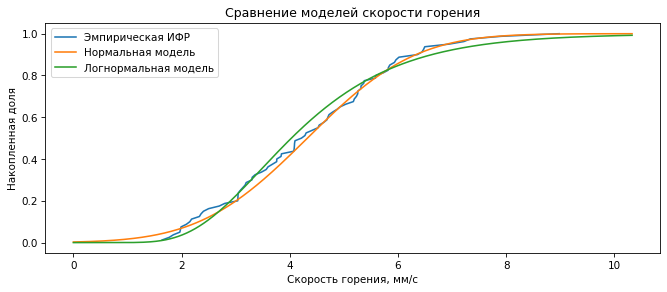

μ нормальной модели: 4.325 мм/с
σ нормальной модели: 1.566 мм/с
Среднее логарифма скорости: 1.393
Стандартное отклонение логарифма: 0.388


In [141]:
from scipy import stats

v_mu, v_sigma = stats.norm.fit(v_ti_cu)

v_shape, v_loc, v_scale = stats.lognorm.fit(
    v_ti_cu,
    floc=0
)

v_grid = np.linspace(0, v_ti_cu.max() * 1.15, 400)

plt.figure(figsize=(9, 4))

v_cdf.plot(label="Эмпирическая ИФР")

plt.plot(
    v_grid,
    stats.norm.cdf(v_grid, loc=v_mu, scale=v_sigma),
    label="Нормальная модель"
)

plt.plot(
    v_grid,
    stats.lognorm.cdf(
        v_grid,
        s=v_shape,
        loc=v_loc,
        scale=v_scale
    ),
    label="Логнормальная модель"
)

plt.xlabel("Скорость горения, мм/с")
plt.ylabel("Накопленная доля")
plt.title("Сравнение моделей скорости горения")
plt.legend()
plt.tight_layout()
plt.show()

print(f"μ нормальной модели: {v_mu:.3f} мм/с")
print(f"σ нормальной модели: {v_sigma:.3f} мм/с")
print(f"Среднее логарифма скорости: {np.log(v_scale):.3f}")
print(f"Стандартное отклонение логарифма: {v_shape:.3f}")

Обе модели близки к эмпирической ИФР в центральной части
распределения. При скоростях около 6-7 мм/с модельные кривые
проходят ниже эмпирической: модели дают большую долю высоких
скоростей, чем наблюдается в данных.

Для нормальной модели μ = 4,325 мм/с, σ = 1,566 мм/с.
Для логнормальной модели среднее логарифма скорости равно 1,393,
стандартное отклонение логарифма - 0,388.

Сравним накопленные доли при нескольких порогах скорости.

In [142]:
v_thresholds = np.array([3, 4, 5, 6])

v_probability_comparison = pd.DataFrame({
    "Порог, мм/с": v_thresholds,
    "Эмпирическая ИФР": [
        (v_ti_cu <= value).mean()
        for value in v_thresholds
    ],
    "Нормальная модель": stats.norm.cdf(
        v_thresholds,
        loc=v_mu,
        scale=v_sigma
    ),
    "Логнормальная модель": stats.lognorm.cdf(
        v_thresholds,
        s=v_shape,
        loc=v_loc,
        scale=v_scale
    )
})

display(v_probability_comparison.round(4))

,"Порог, мм/с",Эмпирическая ИФР,Нормальная модель,Логнормальная модель
0,3,0.1875,0.1988,0.2239
1,4,0.4250,0.4179,0.4927
2,5,0.6500,0.6668,0.7110
3,6,0.8750,0.8576,0.8475


При выбранных порогах нормальная модель точнее воспроизводит
накопленные доли. Максимальное расхождение составляет около
1,7 процентного пункта, у логнормальной модели - около 7,3.

Например, скорость не превышает 4 мм/с у 42,5% записей.
Нормальная модель даёт 41,79%, логнормальная - 49,27%.
Далее сравним плотности моделей с гистограммой и ядерной
оценкой плотности.

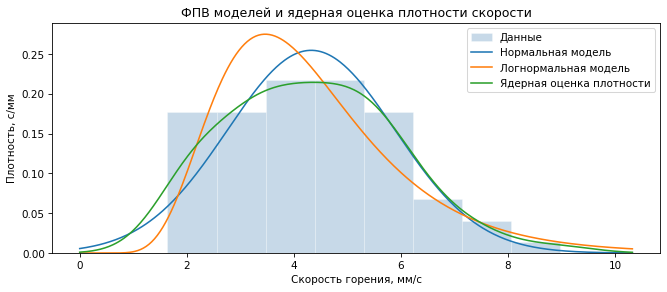

In [143]:
v_kde = stats.gaussian_kde(v_ti_cu)

plt.figure(figsize=(9, 4))

plt.hist(
    v_ti_cu,
    bins="fd",
    density=True,
    alpha=0.3,
    color="steelblue",
    edgecolor="white",
    label="Данные"
)

plt.plot(
    v_grid,
    stats.norm.pdf(v_grid, loc=v_mu, scale=v_sigma),
    label="Нормальная модель"
)

plt.plot(
    v_grid,
    stats.lognorm.pdf(
        v_grid,
        s=v_shape,
        loc=v_loc,
        scale=v_scale
    ),
    label="Логнормальная модель"
)

plt.plot(
    v_grid,
    v_kde(v_grid),
    label="Ядерная оценка плотности"
)

plt.xlabel("Скорость горения, мм/с")
plt.ylabel("Плотность, с/мм")
plt.title("ФПВ моделей и ядерная оценка плотности скорости")
plt.legend()
plt.tight_layout()
plt.show()

Ядерная оценка плотности имеет широкий максимум около 4-5 мм/с.
Нормальная модель даёт более высокий и узкий пик.
Пик логнормальной модели смещён в сторону меньших скоростей,
а правый хвост длиннее. Обе модели сглаживают особенности данных.

Проверим, как скорость связана с давлением кислорода
для каждого из пяти сплавов.

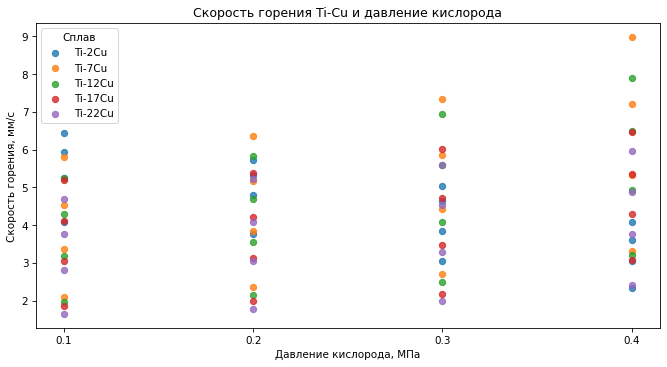

In [144]:
plt.figure(figsize=(9, 5))

for material in ti_cu_materials:
    group = burning_ti_cu.loc[
        burning_ti_cu["material"] == material
    ]

    plt.scatter(
        group["oxygen_pressure_mpa"],
        group["burning_rate_mm_s"],
        label=material,
        alpha=0.8
    )

plt.xlabel("Давление кислорода, МПа")
plt.ylabel("Скорость горения, мм/с")
plt.title("Скорость горения Ti-Cu и давление кислорода")
plt.xticks([0.1, 0.2, 0.3, 0.4])
plt.legend(title="Сплав")
plt.tight_layout()
plt.show()

При каждом давлении наблюдается значительный разброс скоростей.
У Ti-7Cu и Ti-12Cu верхние значения растут с давлением,
у Ti-2Cu заметна обратная тенденция. Рассчитаем корреляции
по всей группе и отдельно для каждого сплава.

In [145]:
v_correlations = []

for name, group in [
    ("Все записи", burning_ti_cu),
    *list(burning_ti_cu.groupby("material"))
]:
    pressure = group["oxygen_pressure_mpa"]
    speed = group["burning_rate_mm_s"]

    v_correlations.append({
        "Группа": name,
        "Количество записей": len(group),
        "Пирсон": pressure.corr(speed, method="pearson"),
        "Спирмен": pressure.corr(speed, method="spearman")
    })

v_correlations = pd.DataFrame(v_correlations).set_index("Группа")

display(v_correlations.round(3))

,Количество записей,Пирсон,Спирмен
Группа,,,
Все записи,80,0.205,0.169
Ti-12Cu,16,0.436,0.424
Ti-17Cu,16,0.339,0.376
Ti-22Cu,16,0.287,0.297
Ti-2Cu,16,-0.727,-0.740
Ti-7Cu,16,0.436,0.388


По всей группе связь давления со скоростью слабая:
коэффициент Пирсона равен 0,205, Спирмена - 0,169.

Для Ti-2Cu связь отрицательная: коэффициенты составляют
-0,727 и -0,740. Для остальных сплавов связь положительная,
коэффициент Пирсона находится в пределах 0,287-0,436.
Общий коэффициент скрывает различия между составами.

Стандартизируем давление и скорость. Проверим, изменится ли
корреляция Пирсона после преобразования.

In [146]:
v_pair = burning_ti_cu[[
    "oxygen_pressure_mpa",
    "burning_rate_mm_s"
]].copy()

v_standardized = (
    (v_pair - v_pair.mean())
    / v_pair.std(ddof=0)
)

display(
    pd.DataFrame({
        "Среднее": v_standardized.mean(),
        "Стандартное отклонение": v_standardized.std(ddof=0)
    }).round(6)
)

print(
    "Пирсон до стандартизации:",
    round(v_pair.corr().iloc[0, 1], 3)
)

print(
    "Пирсон после стандартизации:",
    round(v_standardized.corr().iloc[0, 1], 3)
)

,Среднее,Стандартное отклонение
oxygen_pressure_mpa,0.0,1.0
burning_rate_mm_s,0.0,1.0


Пирсон до стандартизации: 0.205
Пирсон после стандартизации: 0.205


После стандартизации средние обоих признаков равны нулю,
стандартные отклонения - единице. Корреляция Пирсона
сохранилась: 0,205.

### Independence & Estimations

Перейдём к оцениванию среднего. Будем случайно выбирать записи
из группы 80 скоростей с возвращением и без возвращения.
Для каждого объёма повторим отбор 1000 раз и сравним разброс
выборочных средних.

In [ ]:
v_population = v_ti_cu.to_numpy()
v_population_mean = v_population.mean()
v_population_std = v_population.std(ddof=0)
v_population_size = len(v_population)

v_sample_sizes = [5, 10, 20, 40, 60, 80]
v_repeats = 1000
v_rng = np.random.default_rng(48)

v_mean_results = []

for n in v_sample_sizes:
    means_with = v_rng.choice(
        v_population,
        size=(v_repeats, n),
        replace=True
    ).mean(axis=1)

    means_without = np.array([
        v_rng.choice(v_population, size=n, replace=False).mean()
        for _ in range(v_repeats)
    ])

    for scheme, estimates, theoretical_se in [
        (
            "С возвращением",
            means_with,
            v_population_std / np.sqrt(n)
        ),
        (
            "Без возвращения",
            means_without,
            v_population_std / np.sqrt(n)
            * np.sqrt(
                (v_population_size - n)
                / (v_population_size - 1)
            )
        )
    ]:
        v_mean_results.append({
            "Объём выборки": n,
            "Отбор": scheme,
            "Среднее оценок, мм/с": estimates.mean(),
            "Средняя ошибка, мм/с": (
                estimates.mean() - v_population_mean
            ),
            "Стандартное отклонение оценок, мм/с": (
                estimates.std(ddof=0)
            ),
            "Теоретическая стандартная ошибка, мм/с": theoretical_se
        })

v_mean_estimation = pd.DataFrame(v_mean_results)

print(f"Среднее совокупности: {v_population_mean:.3f} мм/с")
display(v_mean_estimation.round(3))

Среднее совокупности: 4.325 мм/с


,Объём выборки,Отбор,"Среднее оценок, мм/с","Средняя ошибка, мм/с","Стандартное отклонение оценок, мм/с","Теоретическая стандартная ошибка, мм/с"
0,5,С возвращением,4.303,-0.021,0.686,0.700
1,5,Без возвращения,4.307,-0.018,0.669,0.682
2,10,С возвращением,4.304,-0.020,0.509,0.495
3,10,Без возвращения,4.278,-0.047,0.459,0.466
4,20,С возвращением,4.325,-0.000,0.359,0.350
5,20,Без возвращения,4.357,0.032,0.295,0.305
6,40,С возвращением,4.317,-0.008,0.242,0.248
7,40,Без возвращения,4.323,-0.002,0.174,0.176
8,60,С возвращением,4.329,0.004,0.202,0.202
9,60,Без возвращения,4.316,-0.009,0.099,0.102


При всех объёмах среднее оценок близко к среднему совокупности
4,325 мм/с. С увеличением выборки разброс средних уменьшается,
а полученные стандартные отклонения близки к теоретическим.

Без возвращения разброс меньше. При n = 80 выборка содержит
всю выбранную совокупность, поэтому среднее всегда одинаково
и стандартная ошибка равна нулю. С возвращением при том же
объёме разброс сохраняется: записи могут повторяться.

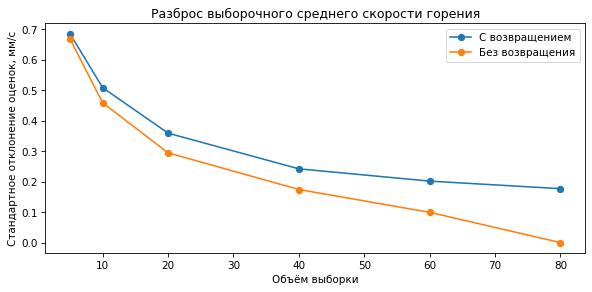

In [148]:
plt.figure(figsize=(8, 4))

for scheme in ["С возвращением", "Без возвращения"]:
    group = v_mean_estimation.loc[
        v_mean_estimation["Отбор"] == scheme
    ]

    plt.plot(
        group["Объём выборки"],
        group["Стандартное отклонение оценок, мм/с"],
        marker="o",
        label=scheme
    )

plt.xlabel("Объём выборки")
plt.ylabel("Стандартное отклонение оценок, мм/с")
plt.title("Разброс выборочного среднего скорости горения")
plt.legend()
plt.tight_layout()
plt.show()

Оценим дисперсию по выборкам с возвращением. Сравним оценки
с делителями n и n-1. Для каждого объёма выполним 1000 повторений.


In [149]:
v_population_variance = v_population.var(ddof=0)
v_variance_rng = np.random.default_rng(49)

v_variance_results = []

for n in v_sample_sizes:
    samples = v_variance_rng.choice(
        v_population,
        size=(v_repeats, n),
        replace=True
    )

    variance_n = samples.var(axis=1, ddof=0)
    variance_corrected = samples.var(axis=1, ddof=1)

    rmse = np.sqrt(
        np.mean(
            (variance_corrected - v_population_variance) ** 2
        )
    )

    v_variance_results.append({
        "Объём выборки": n,
        "Средняя оценка с делителем n, (мм/с)²": (
            variance_n.mean()
        ),
        "Средняя оценка с делителем n-1, (мм/с)²": (
            variance_corrected.mean()
        ),
        "Дисперсия совокупности, (мм/с)²": (
            v_population_variance
        ),
        "Относительная RMSE, %": (
            100 * rmse / v_population_variance
        )
    })

v_variance_estimation = pd.DataFrame(v_variance_results)

display(v_variance_estimation.round(3))

,Объём выборки,"Средняя оценка с делителем n, (мм/с)²","Средняя оценка с делителем n-1, (мм/с)²","Дисперсия совокупности, (мм/с)²","Относительная RMSE, %"
0,5,1.958,2.447,2.453,67.042
1,10,2.189,2.432,2.453,46.933
2,20,2.350,2.474,2.453,31.667
3,40,2.409,2.470,2.453,21.777
4,60,2.416,2.457,2.453,17.060
5,80,2.428,2.459,2.453,14.709


Оценка с делителем n занижает дисперсию, особенно при малых
выборках. При n = 5 её среднее равно 1,958 (мм/с)²,
тогда как дисперсия совокупности составляет 2,453 (мм/с)².
Исправленная оценка в среднем близка к этому значению
при всех рассмотренных объёмах.

С ростом n относительная RMSE исправленной оценки уменьшается
с 67,0% до 14,7%. Даже при n = 80 ошибка сохраняется:
отбор с возвращением допускает повторение записей.

Проверим две гипотезы критерием Шапиро-Уилка:
нормальность скорости и нормальность её логарифма.
Вторая проверка соответствует логнормальной модели скорости.
Уровень значимости - α = 0,05.



In [150]:
v_alpha = 0.05
v_normality_results = []

for name, values in [
    ("Скорость", v_ti_cu),
    ("Логарифм скорости", np.log(v_ti_cu))
]:
    test = stats.shapiro(values)

    v_normality_results.append({
        "Проверяемая величина": name,
        "W": test.statistic,
        "p-значение": test.pvalue,
        "Решение при α = 0,05": (
            "H₀ отвергается"
            if test.pvalue < v_alpha
            else "Оснований отвергнуть H₀ недостаточно"
        )
    })

display(
    pd.DataFrame(v_normality_results)
    .set_index("Проверяемая величина")
    .round(6)
)

,W,p-значение,"Решение при α = 0,05"
Проверяемая величина,,,
Скорость,0.978079,0.185342,Оснований отвергнуть H₀ недостаточно
Логарифм скорости,0.970353,0.059767,Оснований отвергнуть H₀ недостаточно


Для скорости p = 0,185, для её логарифма p = 0,060.
На уровне значимости 0,05 оснований отвергнуть обе гипотезы
недостаточно. Это не доказывает соответствие выбранным законам
распределения.

Нормальную модель используем как приближение для этой группы:
на выбранных порогах она точнее воспроизводит эмпирическую ИФР.
Логнормальная модель также остаётся возможным описанием данных.

При моделировании отбор с возвращением обеспечивает независимость
выборов: вероятность выбора каждой записи остаётся равной 1/80.
Без возвращения выборы зависимы, поскольку набор доступных
записей меняется. Независимость исходных экспериментальных
наблюдений по этим расчётам установить нельзя.

## Lab resume

### cat_mark_table

#Глоссарий
- **EDA (exploratory data analysis)**  — разведочный анализ данных: изучение их структуры, характеристик и закономерностей с помощью статистик и графиков.
- **Distribution (распределение)**  — описание того, какие значения встречаются в наборе данных и как часто встречается каждое значение.
- **Квартили** — три значения, разделяющие упорядоченные данные
  на четыре примерно равные по численности части:
  Q₁ — 25%, Q₂ — медиана, Q₃ — 75%.
- **Межквартильный размах (IQR)** — разность Q₃ − Q₁;
  ширина интервала, содержащего центральные 50% данных.
- **Среднее (mean)** — сумма всех значений, делённая на их количество.
  Чувствительно к крайним значениям.
- **Медиана (median)** — центральное значение упорядоченных данных.
  При чётном количестве наблюдений — среднее двух центральных значений.
- **Гистограмма** — график распределения, в котором значения объединены
  в интервалы. При одинаковой ширине интервалов высота столбцов может
  показывать число или долю попавших в них наблюдений.
- **Правосторонняя асимметрия** — форма распределения с более длинным
  хвостом со стороны больших значений.
- **Потенциальный выброс** — наблюдение, заметно удалённое от основной
  части данных и выделенное для проверки. Может быть связано
  с ошибкой, редким событием или особенностями условий наблюдения.
- **Стандартное отклонение (std)** — мера разброса значений вокруг
  среднего, равная квадратному корню из дисперсии. Выражается
  в тех же единицах, что и исследуемая величина.
- **Частота** — число появлений значения в данных.
- **Таблица частот** — таблица значений и числа их появлений.
- **Относительная частота** — частота значения, делённая на общее
  число наблюдений.
- **Функция вероятности (probability mass function, PMF)** — функция,
  сопоставляющая каждому возможному значению дискретной случайной
  величины его вероятность.
- **Нормированный (normalized)** — набор вероятностей, сумма которых равна 1.
- **Интегральная функция распределения, ИФР (cumulative distribution function, CDF)** —
  функция, которая сопоставляет некоторое значение с долей значений
  распределения, меньших или равных этому значению.
- **Логнормальное распределение (lognormal distribution)** —
  теоретическое распределение, часто используемое для моделирования
  данных, описываемых скошенной вправо колоколообразной кривой.
- **Ядерная оценка плотности, ЯОП (kernel density estimation, KDE)** —
  метод оценки ФПВ на основе выборки.
- **Диаграмма рассеяния (scatter plot)** - график, на котором
  каждая точка показывает пару значений двух переменных.
- **Независимость (independence)** - свойство случайных величин,
  при котором информация о значении одной не меняет распределение
  вероятностей другой.
- **Оценка (estimation)** - определение неизвестных параметров
  генеральной совокупности по выборочным данным.
- **Коэффициент корреляции Пирсона (Pearson correlation coefficient)** -
  статистический показатель, который измеряет силу и знак
  (положительный или отрицательный) линейной связи между двумя переменными.
- **Ранговая корреляция (rank correlation)** -
  робастный способ количественной оценки связи при помощи рангов
  значений вместо самих значений.
- **Стандартная оценка (standard score)** -
  величина, которая, пройдя процедуру стандартизации,
  выражается в единицах стандартного отклонения от среднего значения.
- **Дисперсия (variance)** - математическое ожидание квадрата
  отклонения случайной величины от её математического ожидания.
- **Несмещённая оценка (unbiased estimator)** - оценка,
  математическое ожидание которой равно оцениваемому параметру.
- **Среднеквадратическая ошибка (root mean squared error, RMSE)** -
  квадратный корень из среднего квадрата отклонений оценок
  от истинного значения параметра.
- **Состоятельная оценка (consistent estimator)** -
  оценка, которая сходится по вероятности к оцениваемому параметру
  при неограниченном увеличении объёма выборки.
- **Неравенство Чебышёва (Chebyshev’s inequality)** -
  неравенство, ограничивающее вероятность отклонения случайной
  величины от её математического ожидания:
  P(|X − E[X]| ≥ ε) ≤ Var(X)/ε².
- **Проверка гипотез (hypothesis testing)** -
  набор методов для проверки правдоподобности того, что наблюдаемый
  эффект может быть следствием случайной выборки.
- **Статистика критерия (test statistic)** -
  статистический показатель, используемый при проверке гипотезы
  для количественной оценки величины наблюдаемого эффекта.
- **p-значение (p-value)** -
  вероятность появления эффекта величиной с тот, который наблюдается
  в условиях нулевой гипотезы.
- **Логарифмическая шкала (logarithmic scale)** - шкала, на которой
  равным расстояниям соответствует одинаковое отношение значений.

# Список использованных источников

1. Дауни А. Думай как аналитик. Статистика и данные с примерами на Python. 3-е изд. / пер. с англ. Е. Суворкин; науч. ред. К. Быков. — Астана : Спринт Бук, 2026. — 304 с. : ил. — ISBN 978-601-12-8917-7.

2. Лагутин М. Б. Наглядная математическая статистика : учебное пособие. — 2-е изд., испр. — М. : БИНОМ. Лаборатория знаний, 2009. — 472 с. : ил. — ISBN 978-5-94774-996-0.

3. Wang P., Ke H., Xue Y. An integrated database of combustion properties of metallic materials // Scientific Data. — 2026. — Vol. 13. — Article 460. — DOI: 10.1038/s41597-026-06862-8.

4. Wang P., Ke H., Xue Y. CombustionData [Электронный ресурс]. — GitHub, 2026. — URL: https://github.com/wpl2000/CombustionData.